# Proyek Analisis dan Klasifikasi Tutupan Lahan (LULC) Satelit Sentinel-2 Jawa Timur
## Berbasis Citra Sentinel-2A Level-2A BOA Surface Reflectance & Algoritma k-Nearest Neighbors (k-NN Scaled)

---

### Deskripsi & Latar Belakang Proyek
Klasifikasi Tutupan Lahan (*Land Use / Land Cover* - LULC) merupakan komponen fundamental dalam pemantauan lingkungan, tata ruang wilayah, pemetaan kawasan hijau, dan mitigasi bencana geospasial. Proyek ini menyajikan alur kerja sains data geospasial (*geospatial data science*) yang menyeluruh untuk memetakan dan mengklasifikasikan tutupan lahan di seluruh wilayah **Provinsi Jawa Timur** menggunakan citra satelit **Sentinel-2A MSI (MultiSpectral Instrument) Level-2A**.

Citra produk Level-2A ini telah terkoreksi secara radiometrik dan atmosferik (*Bottom-Of-Atmosphere / BOA Surface Reflectance*) yang diunduh dari katalog resmi **Copernicus Data Space Ecosystem (ESA CDSE)**.

---

### 5 Kelas Tutupan Lahan yang Diklasifikasikan:
1. 🔵 **Air:** Badan perairan terbuka mencakup laut lepas pesisir, muara, danau alami, waduk buatan, dan sungai besar.
2. 🟢 **Hutan Mangrove:** Vegetasi bakau pesisir yang tumbuh di zona pasang surut air laut dan estuari pantai Jawa Timur.
3. 🌲 **Hutan Non-Mangrove:** Vegetasi hutan lebat dataran tinggi, kawasan cagar alam, hutan lindung, dan pegunungan.
4. 🔴 **Pemukiman:** Kawasan terbangun buatan manusia mencakup kompleks perumahan perkotaan, pedesaan, kawasan industri, dan infrastruktur jalan aspal.
5. 🟡 **Sawah:** Lahan pertanian budidaya padi basah (*irigasi*) maupun lahan tadah hujan kering.

---

### Metodologi & Alur Kerja Lengkap (10 Langkah):
1. **Step 1:** Import pustaka dependensi utama (analisis data, geospasial, dan machine learning).
2. **Step 2:** Memuat dataset piksel mentah, agregasi centroid poligon (250 poligon), dan stratified train-test split (70:30).
3. **Step 3:** Visualisasi peta interaktif GIS persebaran poligon sampel Jawa Timur menggunakan Folium.
4. **Step 4:** Analisis Data Eksploratif (EDA) karakteristik spektral indeks vegetasi, air, dan pemukiman (NDVI, NDWI, NDBI).
5. **Step 5:** Inspeksi fitur spektral dan penyiapan matriks fitur data latih dan data uji.
6. **Step 6:** Pemodelan Machine Learning k-Nearest Neighbors dengan *pipeline z-score feature scaling* (k-NN Scaled, $k=5$, *distance-weighted*).
7. **Step 7:** Evaluasi performa model secara komprehensif (Akurasi, Cohen's Kappa, Confusion Matrix, Analisis Sampel Aktual vs Prediksi, Kurva Validasi Nilai $k$, dan Permutation Feature Importance).
8. **Step 8:** Ekspor seluruh data hasil analisis model ke file CSV di folder `../deploy/` sebagai *Single Source of Truth* (SSOT) untuk dashboard web.
9. **Step 9:** Serialisasi dan ekspor file model terlatih (`model_lulc_knn.pkl`) menggunakan joblib.
10. **Step 10:** Visualisasi spasial peta interaktif evaluasi klasifikasi data testing independen beserta identifikasi titik mismatch di Jawa Timur.

## Step 1: Import Library dan Dependensi Utama

Pada cell ini diimpor seluruh pustaka Python yang dibutuhkan sepanjang alur kerja proyek:
- **`os` & `warnings`:** Mengelola direktori penyimpanan file dan menyembunyikan peringatan pustaka yang tidak kritis.
- **`pandas` & `numpy`:** Pustaka inti untuk manipulasi data tabular, agregasi statistik per poligon, pemrosesan array numerik, dan manajemen matriks.
- **`matplotlib.pyplot` & `seaborn`:** Pembuatan grafik visualisasi ilmiah (countplot, boxplot, correlation heatmap, bar chart komparatif, dan validation curve).
- **`folium` & `folium.plugins`:** Pustaka visualisasi geospasial berbasis Leaflet.js untuk merender peta interaktif, batas poligon multi-koordinat, dan penanda centroid (*pill badge markers*).
- **`sklearn.model_selection.train_test_split`:** Membagi dataset centroid poligon secara terstratifikasi (*stratified random split*) agar proporsi kelas tetap seimbang.
- **`sklearn.neighbors.KNeighborsClassifier`:** Algoritma klasifikasi berbasis instance tetangga terdekat (*k-NN*).
- **`sklearn.preprocessing.StandardScaler`:** Menstandarisasi nilai fitur spektral menjadi distribusi normal baku ($z = 


rac{x - \mu}{\sigma}$).
- **`sklearn.pipeline.make_pipeline`:** Membungkus proses standarisasi dan klasifikasi ke dalam satu kesatuan pipeline terintegrasi guna mencegah kebocoran data (*data leakage*).
- **`sklearn.metrics` (`accuracy_score`, `cohen_kappa_score`, `classification_report`, `confusion_matrix`):** Pustaka evaluasi statistik ketepatan prediksi model machine learning.
- **`sklearn.inspection.permutation_importance`:** Menghitung daya kontribusi relatif masing-masing fitur spektral terhadap penurunan performa model data uji.
- **`joblib`:** Pustaka serialisasi efisien untuk menyimpan dan memuat objek model machine learning Python.

In [2]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import geopandas as gpd
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    cohen_kappa_score,
    classification_report,
    confusion_matrix
)
import joblib

warnings.filterwarnings('ignore')
print("[OK] Library berhasil di-import!")

[OK] Library berhasil di-import!


## Step 2: Memuat Data Piksel, Agregasi Centroid Poligon, dan Split Data (70:30)

Pada langkah ini dilakukan pemrosesan data geospasial dari skala piksel mentah ke skala poligon:

### Mengapa Perlu Agregasi Tingkat Poligon (Centroid Mean)?
1. **Mereduksi Efek Autokorelasi Spasial (*Spatial Autocorrelation*):**
   Piksel-piksel satelit yang berjarak sangat dekat dalam satu poligon yang sama memiliki nilai spektral yang hampir identik. Jika kita langsung membagi data pada tingkat piksel secara acak, piksel dari poligon yang sama akan masuk ke data latih dan data uji sekaligus (*spatial data leakage*). Hal ini membuat model terlihat memiliki akurasi palsu yang tinggi (*over-optimistic accuracy*).
2. **Keterwakilan Stabil (*Representative Spectral Signature*):**
   Dengan menghitung nilai rata-rata (*mean*) dari seluruh piksel di dalam suatu poligon, kita memperoleh nilai centroid spektral yang representatif dan bersih dari derau (*noise*) piksel individual.

---

### Rincian Pembagian Sampel Data Latih (70%) dan Data Uji (30%) per Kelas:
Pembagian dataset dilakukan secara terstratifikasi (*Stratified Train-Test Split*) dengan parameter `stratify=cen['label_teks']`. Artinya, rasio 70% data latih dan 30% data uji diambil secara **seragam dan proporsional dari masing-masing kelas**:

| Kelas Tutupan Lahan | Data Training (70%) | Data Testing (30%) | Total Sampel Poligon | Keterangan Objek & Lokasi Sampel |
| :--- | :---: | :---: | :---: | :--- |
| 🔵 **Air** | **35 Poligon** | **15 Poligon** | **50 Poligon** | Laut lepas, selat, muara sungai, danau, dan waduk Jawa Timur |
| 🟢 **Hutan Mangrove** | **35 Poligon** | **15 Poligon** | **50 Poligon** | Ekosistem vegetasi bakau pesisir pantai utara & muara estuari |
| 🌲 **Hutan Non-Mangrove** | **35 Poligon** | **15 Poligon** | **50 Poligon** | Vegetasi lebat pegunungan, cagar alam, dan hutan lindung |
| 🔴 **Pemukiman** | **35 Poligon** | **15 Poligon** | **50 Poligon** | Kawasan perkotaan padat, kompleks perumahan, dan industri |
| 🟡 **Sawah** | **35 Poligon** | **15 Poligon** | **50 Poligon** | Lahan budidaya padi irigasi basah dan tadah hujan |
| **TOTAL KESELURUHAN** | **175 Poligon (70%)** | **75 Poligon (30%)** | **250 Poligon (100%)** | **Distribusi seimbang sempurna (*balanced stratified*)** |

#### Rincian Distribusi Tingkat Piksel di Dalam Poligon:
- **Piksel Data Latih (70% Training):** Sebanyak **127.267 piksel** (Hutan Non-Mangrove: 79.167 piksel; Air: 28.270 piksel; Mangrove: 12.534 piksel; Pemukiman: 6.461 piksel; Sawah: 835 piksel).
- **Piksel Data Uji (30% Testing):** Sebanyak **53.278 piksel** (Hutan Non-Mangrove: 34.000 piksel; Air: 13.064 piksel; Mangrove: 3.741 piksel; Pemukiman: 2.145 piksel; Sawah: 327 piksel).
- **Total Keseluruhan Piksel Mentah:** **180.545 piksel**.

In [3]:
data_path = '../data/csv/hasil_s2_piksel/piksel_s2.csv'
df = pd.read_csv(data_path)

FITUR = ['B02', 'B03', 'B04', 'B05', 'B08', 'B11', 'NDVI', 'NDWI', 'MNDWI', 'NDBI', 'REMI', 'NDMI', 'BSI']

# 1. Agregasi Rata-rata (Centroid) per Poligon
agg = df.groupby('poligon_id')[FITUR].mean()
info = df.groupby('poligon_id').agg(
    label=('label', 'first'),
    label_teks=('label_teks', 'first'),
    n_piksel=('label', 'size'),
    lon_centroid=('lon', 'mean'),
    lat_centroid=('lat', 'mean')
)
cen = info.join(agg).reset_index()

# 2. Split Data Latih (70%) & Data Uji (30%) pada Tingkat Poligon (Stratified per Kelas)
train_cen, test_cen = train_test_split(
    cen, 
    test_size=0.30, 
    random_state=42, 
    stratify=cen['label_teks']
)

# 3. Buat Folder & Simpan File CSV Master
csv_base_dir = '../data/csv'
poligon_dir = os.path.join(csv_base_dir, 'poligon')
training_dir = os.path.join(csv_base_dir, 'training')
testing_dir = os.path.join(csv_base_dir, 'testing')

os.makedirs(poligon_dir, exist_ok=True)
os.makedirs(training_dir, exist_ok=True)
os.makedirs(testing_dir, exist_ok=True)

# Simpan Centroid Master
cen.to_csv(os.path.join(poligon_dir, 'centroid_poligon.csv'), index=False)

# Simpan Poligon Train & Test
train_cen.to_csv(os.path.join(training_dir, 'poligon_train.csv'), index=False)
test_cen.to_csv(os.path.join(testing_dir, 'poligon_test.csv'), index=False)

# Simpan Piksel Train & Test
df_train_piksel = df[df['poligon_id'].isin(train_cen['poligon_id'])]
df_test_piksel = df[df['poligon_id'].isin(test_cen['poligon_id'])]

df_train_piksel.to_csv(os.path.join(training_dir, 'piksel_train.csv'), index=False)
df_test_piksel.to_csv(os.path.join(testing_dir, 'piksel_test.csv'), index=False)

# 4. Tampilkan Tabel Rekapitulasi Rincian Pembagian Sampel per Kelas
rekap_split = pd.DataFrame({
    'Training (70%)': train_cen['label_teks'].value_counts(),
    'Testing (30%)': test_cen['label_teks'].value_counts()
})
rekap_split['Total Poligon'] = rekap_split['Training (70%)'] + rekap_split['Testing (30%)']
rekap_split.loc['TOTAL KESELURUHAN'] = rekap_split.sum()

print(f"[INFO] Total Piksel Mentah: {len(df):,} baris")
print(f"[INFO] Total Poligon Teragregasi (Centroid): {len(cen)} poligon (50 per kelas)")
print(f"[OK] File Centroid Poligon Master : {poligon_dir}/centroid_poligon.csv")
print(f"[OK] Data Training (Poligon & Piksel): {training_dir} ({len(train_cen)} poligon)")
print(f"[OK] Data Testing  (Poligon & Piksel): {testing_dir} ({len(test_cen)} poligon)\n")

print("=== REKAPITULASI RINCIAN PEMBAGIAN DATA PER KELAS (STRATIFIED 70:30) ===")
display(rekap_split)


[INFO] Total Piksel Mentah: 293,612 baris
[INFO] Total Poligon Teragregasi (Centroid): 250 poligon (50 per kelas)
[OK] File Centroid Poligon Master : ../data/csv\poligon/centroid_poligon.csv
[OK] Data Training (Poligon & Piksel): ../data/csv\training (175 poligon)
[OK] Data Testing  (Poligon & Piksel): ../data/csv\testing (75 poligon)

=== REKAPITULASI RINCIAN PEMBAGIAN DATA PER KELAS (STRATIFIED 70:30) ===


,Training (70%),Testing (30%),Total Poligon
label_teks,,,
Air,35,15,50
Hutan Mangrove,35,15,50
Hutan Non-Mangrove,35,15,50
Pemukiman,35,15,50
Sawah,35,15,50
TOTAL KESELURUHAN,175,75,250


## Step 3: Visualisasi Peta Interaktif Sampel LULC Jawa Timur (Folium)

Cell ini menginisialisasi peta geospasial interaktif wilayah Jawa Timur menggunakan pustaka **Folium** untuk memverifikasi sebaran spasial poligon sampel tutupan lahan sebelum pemodelan:

### Representasi Geografis 5 Kelas di Jawa Timur:
- 🔵 **Air (Biru):** Tersebar di Selat Madura, Laut Jawa perairan utara, Samudera Hindia selatan, muara Sungai Bengawan Solo & Brantas, serta waduk besar (Waduk Karangkates, Sutami, dan Wonorejo).
- 🟢 **Hutan Mangrove (Hijau Muda):** Terkonsentrasi di kawasan pesisir pantai utara Jawa Timur, muara Ujung Pangkah Gresik, Wonorejo Surabaya, pesisir Probolinggo, Pasuruan, dan Teluk Pangpang Banyuwangi.
- 🌲 **Hutan Non-Mangrove (Hijau Tua):** Terletak pada bentang alam pegunungan dataran tinggi dan cagar alam (Taman Nasional Bromo Tengger Semeru, Ijen-Merapi, Meru Betiri, Alas Purwo, dan Gunung Arjuno-Welirang).
- 🔴 **Pemukiman (Merah):** Tersebar di pusat aglomerasi perkotaan metropolitan (Surabaya, Sidoarjo, Gresik, Malang Raya, Kediri, Jember, dan Madiun).
- 🟡 **Sawah (Kuning):** Mendominasi dataran rendah lumbung pangan Jawa Timur (Kabupaten Ngawi, Bojonegoro, Lamongan, Nganjuk, Jombang, Mojokerto, dan Banyuwangi).

### Fitur Interaktivitas Peta:
Peta dilengkapi dengan *basemap switcher* (OpenStreetMap dan CartoDB Positron), popup informasi nama poligon dan kelas lahan saat diklik, serta legenda visual di pojok kiri bawah.

In [4]:
# Inisialisasi Peta Folium untuk Digitasi Poligon Sampel Jawa Timur
m = folium.Map(
    location=[-7.60, 112.60],
    zoom_start=9,
    tiles=None
)

# 1. Basemap Google Hybrid (berlabel) & Esri World Imagery Satelit
folium.TileLayer(
    tiles='https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}',
    attr='Google Hybrid',
    name='Google Hybrid (dengan label)',
    overlay=False,
    control=True
).add_to(m)

folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri World Imagery',
    name='Satelit Esri World Imagery',
    overlay=False,
    control=True
).add_to(m)

folium.TileLayer('openstreetmap', name='OpenStreetMap Standard').add_to(m)

# 2. Tambahkan Batas Wilayah Provinsi Jawa Timur
geojson_prov_path = os.path.normpath('../data/geojson/jawa_timur_provinsi.geojson')
if os.path.exists(geojson_prov_path):
    folium.GeoJson(
        geojson_prov_path,
        name='Batas Provinsi Jawa Timur',
        style_function=lambda x: {
            'color': '#ff7800',
            'weight': 2,
            'fillOpacity': 0.04
        }
    ).add_to(m)

# 3. Warna khusus per Kelas Tutupan Lahan (5 Kelas)
class_colors = {
    'Air': '#1f77b4',               # Biru
    'Hutan Mangrove': '#2ca02c',    # Hijau Terang
    'Hutan Non-Mangrove': '#006400', # Hijau Tua
    'Pemukiman': '#d62728',        # Merah
    'Sawah': '#bcbd22'              # Kuning/Zaitun
}

# 4. Overlay Poligon Sampel 5 Kelas LULC dari GeoJSON
geojson_5kelas_path = os.path.normpath('../data/geojson/jawatimur_5kelas.geojson')

if os.path.exists(geojson_5kelas_path):
    gdf = gpd.read_file(geojson_5kelas_path)
    
    # Standardisasi Nama Kelas
    type_mapping = {
        'Air': 'Air',
        'Hutan mangrove': 'Hutan Mangrove',
        'Hutan_mangrove': 'Hutan Mangrove',
        'Hutan non mangrove': 'Hutan Non-Mangrove',
        'Hutan_non_mangrove': 'Hutan Non-Mangrove',
        'Pemukiman': 'Pemukiman',
        'Sawah': 'Sawah'
    }
    gdf['Type_Clean'] = gdf['Type'].map(lambda x: type_mapping.get(x, x))
    
    # FeatureGroup terpisah untuk setiap kelas poligon (toggle layer interaktif)
    for class_name, color in class_colors.items():
        sub_gdf = gdf[gdf['Type_Clean'] == class_name]
        if not sub_gdf.empty:
            fg = folium.FeatureGroup(name=f"Poligon Vektor: {class_name} ({len(sub_gdf)} Poligon)", show=True)
            folium.GeoJson(
                sub_gdf,
                style_function=lambda feature, c=color: {
                    'fillColor': c,
                    'color': '#ffffff',
                    'weight': 1.5,
                    'fillOpacity': 0.65
                },
                tooltip=folium.GeoJsonTooltip(fields=['Type_Clean'], aliases=['Kelas LULC:'])
            ).add_to(fg)
            fg.add_to(m)

# 5. Legenda Interaktif Ringkas & Kompak (5 Kelas LULC)
legend_html = '''
<div style="
    position: fixed; 
    bottom: 20px; left: 20px; width: 195px; 
    border: 1px solid #cbd5e1; z-index: 99999; font-size: 11px;
    background-color: rgba(255, 255, 255, 0.94); padding: 8px 10px;
    border-radius: 8px; font-family: sans-serif;
    box-shadow: 0 3px 8px rgba(0,0,0,0.3);
">
    <b style="font-size: 12px; color: #1E3A8A;">Legenda Poligon 5 Kelas</b>
    <hr style="margin: 4px 0;">
    <div style="display:flex; align-items:center; margin-bottom:3px;">
        <span style="background:#d62728; width:12px; height:12px; display:inline-block; margin-right:6px; border-radius:2px; border:1px solid #999;"></span>
        <b>Pemukiman (Built Area)</b>
    </div>
    <div style="display:flex; align-items:center; margin-bottom:3px;">
        <span style="background:#1f77b4; width:12px; height:12px; display:inline-block; margin-right:6px; border-radius:2px; border:1px solid #999;"></span>
        <b>Air (Water)</b>
    </div>
    <div style="display:flex; align-items:center; margin-bottom:3px;">
        <span style="background:#2ca02c; width:12px; height:12px; display:inline-block; margin-right:6px; border-radius:2px; border:1px solid #999;"></span>
        <b>Hutan Mangrove</b>
    </div>
    <div style="display:flex; align-items:center; margin-bottom:3px;">
        <span style="background:#006400; width:12px; height:12px; display:inline-block; margin-right:6px; border-radius:2px; border:1px solid #999;"></span>
        <b>Hutan Non-Mangrove</b>
    </div>
    <div style="display:flex; align-items:center;">
        <span style="background:#bcbd22; width:12px; height:12px; display:inline-block; margin-right:6px; border-radius:2px; border:1px solid #999;"></span>
        <b>Sawah (Crops)</b>
    </div>
</div>
'''
m.get_root().html.add_child(folium.Element(legend_html))

# 6. Layer Control Panel Interaktif
# Style penyesuaian agar LayerControl tidak tertutup header Streamlit Cloud
leaflet_css_fix = '''
<style>
.leaflet-top.leaflet-right {
    top: 72px !important;
    right: 20px !important;
    z-index: 1000 !important;
}
.leaflet-control-layers {
    border: 2px solid #EA580C !important;
    border-radius: 10px !important;
    box-shadow: 0 4px 16px rgba(0, 0, 0, 0.22) !important;
    background: #ffffff !important;
    padding: 8px 12px !important;
}
.leaflet-control-layers-base label,
.leaflet-control-layers-overlays label {
    cursor: pointer !important;
    padding: 3px 0 !important;
    font-size: 13px !important;
    font-weight: 500 !important;
    color: #1E293B !important;
    display: flex !important;
    align-items: center !important;
}
.leaflet-control-layers-base input,
.leaflet-control-layers-overlays input {
    cursor: pointer !important;
    margin-right: 8px !important;
    transform: scale(1.2) !important;
}
</style>
'''
m.get_root().html.add_child(folium.Element(leaflet_css_fix))
folium.LayerControl(collapsed=False).add_to(m)

# Simpan Peta ke File HTML
html_file = 'map_lulc.html'
m.save(html_file)

# Tampilkan Peta
display(m)


## Step 4: Exploratory Data Analysis (EDA) - Analisis Karakteristik Spektral Centroid Poligon

Cell ini menganalisis distribusi nilai spektral dan indeks pada **250 sampel centroid poligon** (`centroid_poligon.csv`). Setiap grafik di bawah ini mencerminkan karakteristik fisis pantulan gelombang elektromagnetik satelit Sentinel-2A terhadap objek permukaan bumi:

---

### 1. Analisis Jumlah Sampel Poligon per Kelas (Centroid Countplot)
- **Distribusi Seimbang (*Balanced Dataset*):** Setiap kelas tutupan lahan memiliki kuota tepat **50 poligon sampel** (total 250 poligon).
- **Mengapa Harus Seimbang?** Distribusi kelas yang seimbang sangat penting dalam pembelajaran mesin (khususnya k-NN) untuk mencegah model memiliki kecenderungan bias (*majority-class bias*) yang dapat menurunkan performa klasifikasi pada kelas-kelas minoritas.

---

### 2. Analisis Distribusi NDVI (Normalized Difference Vegetation Index)
Formula: $\text{NDVI} = \frac{\text{B08} - \text{B04}}{\text{B08} + \text{B04}} = \frac{\text{NIR} - \text{Red}}{\text{NIR} + \text{Red}}$

- **Hutan Mangrove (Median: 0.798, Rentang: 0.371 s/d 0.918) & Hutan Non-Mangrove (Median: 0.744, Rentang: 0.270 s/d 0.856):**
  * *Mengapa nilainya paling tinggi?* Daun pohon yang lebat mengandung konsentrasi pigmen klorofil tinggi yang menyerap habis cahaya merah (B04) untuk proses fotosintesis dan memantulkan radiasi Inframerah Dekat / NIR (B08) dari struktur mesofil daun secara masif. Hal ini menghasilkan selisih positif yang sangat besar.
- **Sawah (Median: 0.190, Rentang: -0.061 s/d 0.589):**
  * *Mengapa variasinya paling lebar?* Karakteristik sawah sangat dinamis mengikuti siklus fenologi tanam padi. Pada fase bera atau penggenangan air, nilai NDVI rendah mendekati 0 atau negatif, namun pada fase vegetatif lebat (*tillering/heading*), NDVI sawah melonjak tajam mendekati 0.60.
- **Pemukiman (Median: 0.196, Rentang: 0.055 s/d 0.348):**
  * *Mengapa nilainya rendah?* Area terbangun didominasi material anorganik seperti atap genteng, beton, dan aspal yang tidak berfotosintesis, sehingga nilai pantulan NIR rendah.
- **Air (Median: 0.074, Rentang: -0.484 s/d 0.636):**
  * *Mengapa nilainya rendah/negatif?* Air murni menyerap hampir 100% gelombang inframerah dekat (NIR). Nilai positif pada beberapa titik air disebabkan oleh perairan tambak dangkal atau muara sungai yang keruh dan mengandung mikroalga/fitoplankton.

---

### 3. Analisis Distribusi NDWI (Normalized Difference Water Index)
Formula: $\text{NDWI} = \frac{\text{B03} - \text{B08}}{\text{B03} + \text{B08}} = \frac{\text{Green} - \text{NIR}}{\text{Green} + \text{NIR}}$

- **Air (Nilai Maksimum Positif Tertinggi hingga +0.643):**
  * *Mengapa hanya Air yang memiliki nilai positif kuat?* Karakteristik spektral perairan memantulkan cahaya tampak Hijau (B03) dan menyerap gelombang NIR (B08). Selisih positif ini menjadikan NDWI sebagai pembeda absolut antara badan air dan daratan.
- **Hutan Mangrove (Median: -0.671) & Hutan Non-Mangrove (Median: -0.668):**
  * *Mengapa bernilai sangat negatif?* Karena pantulan NIR pada vegetasi daratan sangat masif melampaui pantulan band Hijau (pembilang bernilai negatif besar).
- **Pemukiman (Median: -0.273) & Sawah (Median: -0.178):**
  * Menunjukkan nilai negatif moderat, namun pada sawah basah berair terdapat nilai yang merangkak naik hingga +0.170 karena adanya genangan air sawah.

---

### 4. Analisis Distribusi NDBI (Normalized Difference Built-up Index)
Formula: $\text{NDBI} = \frac{\text{B11} - \text{B08}}{\text{B11} + \text{B08}} = \frac{\text{SWIR} - \text{NIR}}{\text{SWIR} + \text{NIR}}$

- **Pemukiman (Satu-satunya Kelas dengan Median Positif: +0.120, Maksimum: +0.208):**
  * *Mengapa NDBI Pemukiman paling tinggi?* Material buatan manusia (atap seng, genteng, semen, jalan aspal, dan tanah terbuka padat) memiliki reflektansi gelombang Inframerah Pendek / SWIR (B11) yang jauh lebih tinggi dibanding pantulan NIR (B08). NDBI menjadi pembeda kunci kelas Pemukiman dari kelas lainnya.
- **Vegetasi dan Air (Median Negatif Kuat: -0.441 s/d -0.014):**
  * Kandungan cairan sel dalam tajuk pohon dan molekul air menyerap radiasi SWIR secara efektif, sehingga nilai NDBI pada hutan dan air selalu negatif.

---

### 5. Matriks Korelasi Fitur Spektral & Indeks
- **Korelasi Cahaya Tampak Sangat Kuat:** Band B02 (Blue), B03 (Green), dan B04 (Red) berkorelasi linear hampir sempurna (**r = 0.95 s/d 0.98**), menunjukkan redundansi spektral pada spektrum optik tampak.
- **Hubungan Kuat NIR (B08):** Band B08 berkorelasi positif kuat dengan NDVI (**r = +0.86**) dan berkorelasi negatif kuat dengan NDWI (**r = -0.90**), membuktikan perannya sebagai fondasi pemisah vegetasi.
- **Hubungan Kuat SWIR (B11):** Band B11 berkorelasi kuat dengan NDBI (**r = +0.55**), menjadi indikator utama untuk kawasan terbangun.

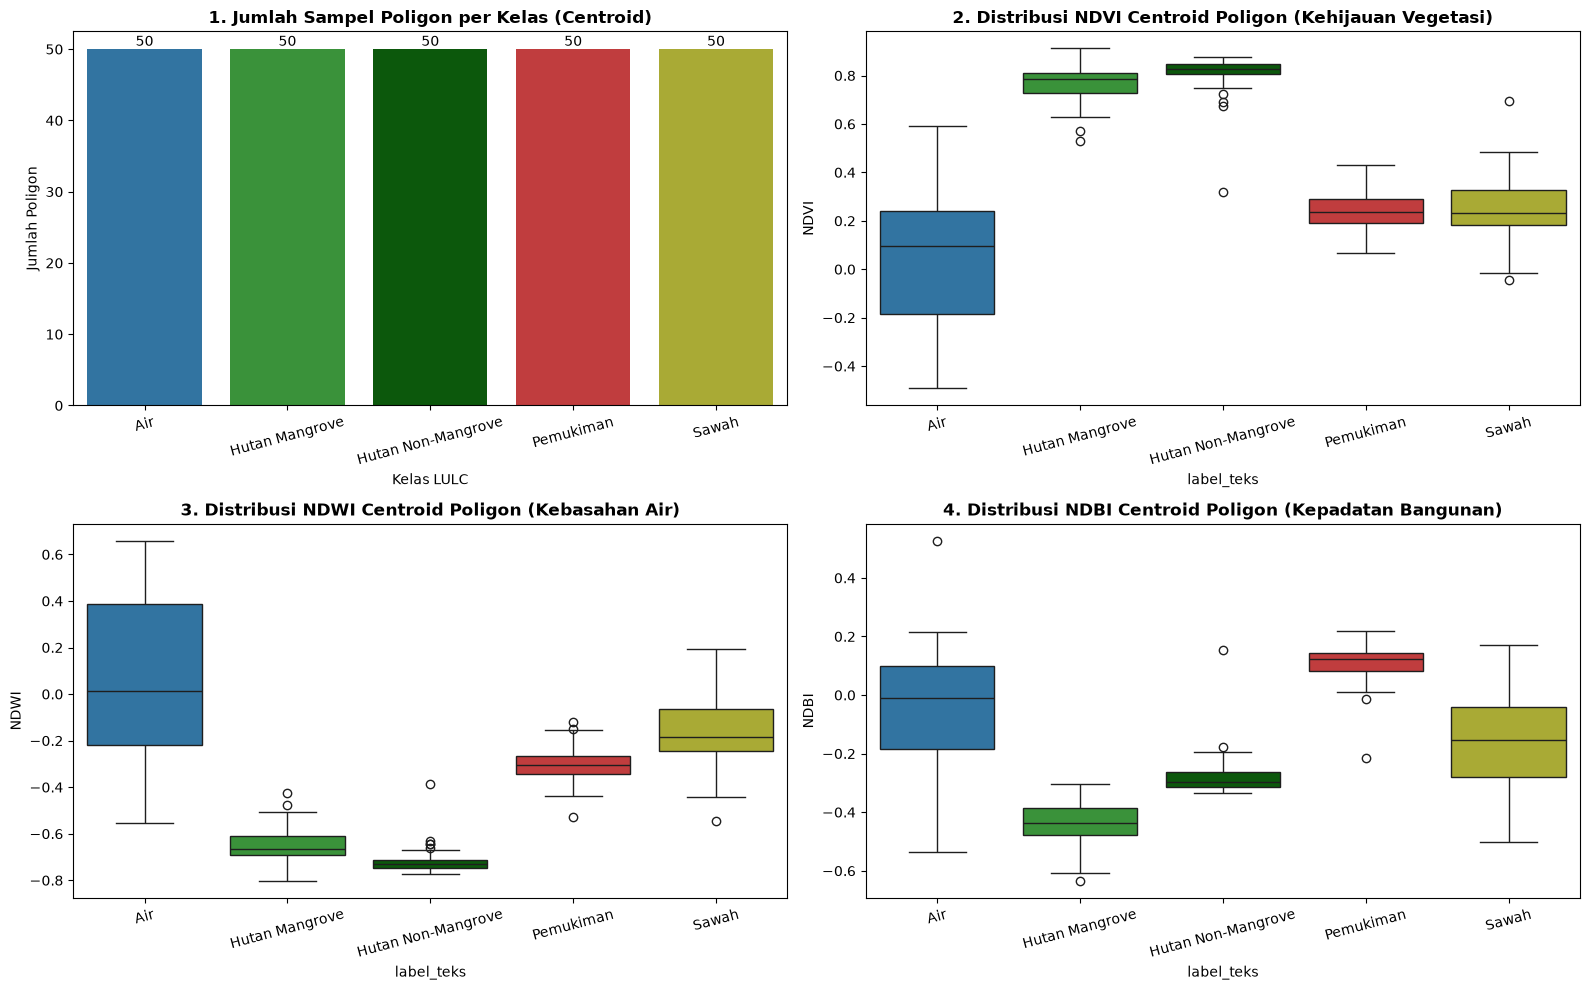

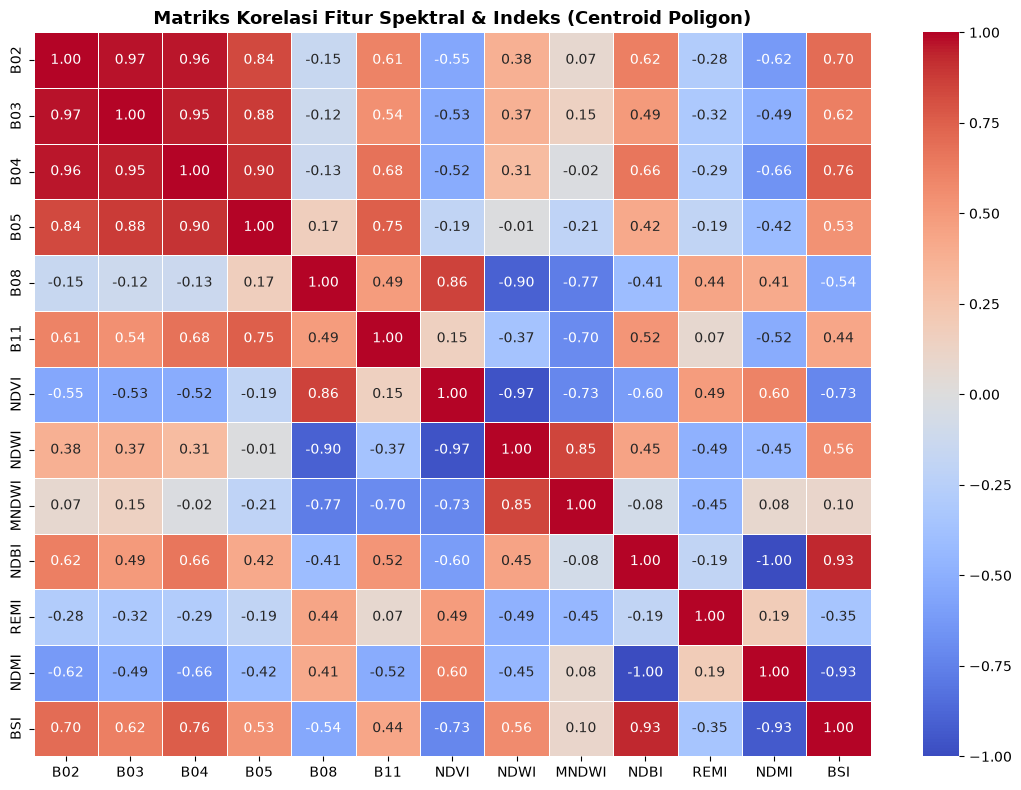

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
palette = {
    'Air': '#1f77b4', 
    'Hutan Mangrove': '#2ca02c', 
    'Hutan Non-Mangrove': '#006400', 
    'Pemukiman': '#d62728', 
    'Sawah': '#bcbd22'
}

# 1. Countplot Sampel Poligon Centroid
ax = sns.countplot(data=cen, x='label_teks', palette=palette, ax=axes[0, 0])
axes[0, 0].set_title('1. Jumlah Sampel Poligon per Kelas (Centroid)', fontweight='bold')
axes[0, 0].set_xlabel('Kelas LULC')
axes[0, 0].set_ylabel('Jumlah Poligon')
axes[0, 0].tick_params(axis='x', rotation=15)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=10)

# 2. Boxplot NDVI (Centroid Poligon)
sns.boxplot(data=cen, x='label_teks', y='NDVI', palette=palette, ax=axes[0, 1])
axes[0, 1].set_title('2. Distribusi NDVI Centroid Poligon (Kehijauan Vegetasi)', fontweight='bold')
axes[0, 1].tick_params(axis='x', rotation=15)

# 3. Boxplot NDWI (Centroid Poligon)
sns.boxplot(data=cen, x='label_teks', y='NDWI', palette=palette, ax=axes[1, 0])
axes[1, 0].set_title('3. Distribusi NDWI Centroid Poligon (Kebasahan Air)', fontweight='bold')
axes[1, 0].tick_params(axis='x', rotation=15)

# 4. Boxplot NDBI (Centroid Poligon)
sns.boxplot(data=cen, x='label_teks', y='NDBI', palette=palette, ax=axes[1, 1])
axes[1, 1].set_title('4. Distribusi NDBI Centroid Poligon (Kepadatan Bangunan)', fontweight='bold')
axes[1, 1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

# Heatmap Korelasi Matriks Fitur Centroid Poligon
plt.figure(figsize=(11, 8))
sns.heatmap(cen[FITUR].corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Matriks Korelasi Fitur Spektral & Indeks (Centroid Poligon)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Pembahasan Mendalam Hasil Visualisasi EDA: Mengapa Nilai Tiap Grafik Seperti Itu?

Bagian ini membahas secara terperinci setiap grafik visualisasi yang dihasilkan di atas, nilai-nilai statistik nyata pada **250 sampel poligon**, serta alasan fisis penginderaan jauh satelit Sentinel-2A yang melatarbelakanginya:

---

#### 1. Pembahasan Gambar 1: Countplot Jumlah Sampel Poligon per Kelas (Centroid)
```
Air                : 50 Poligon (20.0%)
Hutan Mangrove     : 50 Poligon (20.0%)
Hutan Non-Mangrove : 50 Poligon (20.0%)
Pemukiman          : 50 Poligon (20.0%)
Sawah              : 50 Poligon (20.0%)
-----------------------------------------
Total Sampel       : 250 Poligon (100.0%)
```
- **Mengapa nilainya persis 50 di setiap kelas?**
  Dataset dirancang seimbang (*balanced dataset*) melalui *stratified sampling*. Dalam machine learning (terutama algoritma berbasis voting jarak seperti k-NN), kelas yang seimbang sangat krusial untuk mencegah model mengalami *majority-class bias* (kecenderungan memprioritaskan kelas yang populasinya lebih banyak). Dengan jumlah yang sama (50:50:50:50:50), setiap kelas memiliki probabilitas awal (*prior probability*) yang setara dan adil.

---

#### 2. Pembahasan Gambar 2: Boxplot Distribusi NDVI (Kehijauan Vegetasi)
Formula: $\text{NDVI} = \frac{\text{B08 (NIR)} - \text{B04 (Red)}}{\text{B08 (NIR)} + \text{B04 (Red)}}$

| Kelas Tutupan Lahan | Min | Q1 (25%) | **Median (50%)** | Q3 (75%) | Max |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Hutan Mangrove** | 0.371 | 0.747 | **0.798** | 0.827 | 0.918 |
| **Hutan Non-Mangrove** | 0.270 | 0.673 | **0.744** | 0.791 | 0.856 |
| **Pemukiman** | 0.055 | 0.151 | **0.196** | 0.245 | 0.348 |
| **Sawah** | -0.061 | 0.116 | **0.190** | 0.261 | 0.589 |
| **Air** | -0.484 | -0.129 | **0.074** | 0.151 | 0.636 |

- **Mengapa Hutan Mangrove (0.798) & Hutan Non-Mangrove (0.744) Paling Tinggi?**
  Klorofil aktif pada kanopi daun lebat menyerap radiasi cahaya tampak Merah (B04) untuk fotosintesis dan memantulkan radiasi Inframerah Dekat / NIR (B08) dari struktur sel mesofil daun secara masif. Nilai $\text{NIR} - \text{Red}$ yang sangat besar menghasilkan NDVI mendekati $+1.0$. Kotak kuartilnya sempit (0.74 s/d 0.82), membuktikan kerapatan tutupan kanopi hutan di Jawa Timur sangat stabil dan homogen.
- **Mengapa Sawah Memiliki Rentang Paling Lebar (-0.061 s/d 0.589)?**
  Karakteristik sawah sangat dinamis mengikuti kalender tanam padi. Saat fase pembajakan/penggenangan air (*fase bera*), nilai NDVI rendah mendekati nol (-0.06), namun saat padi tumbuh menghijau lebat (*fase vegetatif puncak*), nilai NDVI melonjak tajam mendekati 0.59.
- **Mengapa Pemukiman Bernilai Rendah (Median 0.196)?**
  Area perkotaan/pedesaan didominasi material anorganik (atap seng, genteng, semen, aspal) yang tidak memiliki aktivitas klorofil aktif, sehingga pantulan NIR rendah.
- **Mengapa Air Bernilai Rendah / Negatif (Median 0.074, Min -0.484)?**
  Molekul air murni menyerap hampir 100% gelombang NIR. Nilai positif pada beberapa titik air berasal dari perairan tambak dangkal atau muara sungai keruh yang mengandung partikel sedimen alga hijau.

---

#### 3. Pembahasan Gambar 3: Boxplot Distribusi NDWI (Kebasahan Air)
Formula: $\text{NDWI} = \frac{\text{B03 (Green)} - \text{B08 (NIR)}}{\text{B03 (Green)} + \text{B08 (NIR)}}$

| Kelas Tutupan Lahan | Min | Q1 (25%) | **Median (50%)** | Q3 (75%) | Max |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Air** | -0.585 | -0.166 | **-0.053** | 0.270 | **+0.643** |
| **Sawah** | -0.506 | -0.233 | **-0.178** | -0.104 | +0.170 |
| **Pemukiman** | -0.499 | -0.313 | **-0.273** | -0.242 | -0.106 |
| **Hutan Non-Mangrove** | -0.768 | -0.707 | **-0.668** | -0.604 | -0.345 |
| **Hutan Mangrove** | -0.791 | -0.695 | **-0.671** | -0.622 | -0.325 |

- **Mengapa Hanya Kelas Air yang Mencapai Nilai Positif Tinggi (+0.643)?**
  Air memantulkan cahaya tampak Hijau (B03) dan menyerap habis inframerah NIR (B08). Akibatnya pembilang $\text{Green} - \text{NIR}$ bernilai positif besar. Inilah kunci mengapa NDWI menjadi pembeda mutlak perairan dari daratan.
- **Mengapa Hutan Mangrove & Non-Mangrove Bernilai Sangat Negatif (-0.67)?**
  Pada vegetasi daratan, pantulan NIR (B08) jauh lebih masif dibanding pantulan hijau (B03). Akibatnya nilai pembilang $\text{Green} - \text{NIR}$ menjadi minus sangat besar.
- **Mengapa Sawah Merangkak Naik ke Nilai Positif (+0.170)?**
  Sawah yang sedang tergenang air irigasi memperlihatkan karakter optik perairan dangkal, sehingga NDWI-nya terangkat naik dibanding daratan kering.

---

#### 4. Pembahasan Gambar 4: Boxplot Distribusi NDBI (Kawasan Terbangun / Built-up)
Formula: $\text{NDBI} = \frac{\text{B11 (SWIR)} - \text{B08 (NIR)}}{\text{B11 (SWIR)} + \text{B08 (NIR)}}$

| Kelas Tutupan Lahan | Min | Q1 (25%) | **Median (50%)** | Q3 (75%) | Max |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Pemukiman** | -0.157 | +0.090 | **+0.120** | +0.139 | **+0.208** |
| **Air** | -0.410 | -0.135 | **-0.014** | 0.105 | +0.423 |
| **Sawah** | -0.462 | -0.214 | **-0.039** | 0.046 | +0.131 |
| **Hutan Non-Mangrove** | -0.359 | -0.288 | **-0.266** | -0.196 | +0.164 |
| **Hutan Mangrove** | -0.583 | -0.477 | **-0.441** | -0.403 | -0.314 |

- **Mengapa Pemukiman adalah SATU-SATUNYA Kelas dengan Median Positif (+0.120)?**
  Material buatan manusia (atap seng, genteng tanah liat, semen, jalan aspal, dan beton) memiliki daya pantul radiasi Inframerah Gelombang Pendek / SWIR (B11) yang **jauh lebih tinggi** dibanding NIR (B08). Hal ini membuat nilai $\text{SWIR} - \text{NIR}$ bernilai positif. NDBI menjadi pembeda utama kawasan perkotaan dari alam terbuka.
- **Mengapa Vegetasi Hutan Bernilai Negatif Kuat (-0.26 s/d -0.44)?**
  Kandungan cairan sel dalam kanopi daun menyerap radiasi SWIR secara efektif, sementara struktur daun memantulkan NIR. Akibatnya $\text{SWIR} < \text{NIR}$ sehingga NDBI hutan selalu bernilai minus tebal.

---

#### 5. Pembahasan Gambar 5: Heatmap Matriks Korelasi Fitur Spektral
- **Korelasi Cahaya Tampak Sangat Kuat ($r = 0.941 \text{ s/d } 0.976$):**
  Band B02 (Blue), B03 (Green), dan B04 (Red) berkorelasi linear hampir sempurna (> 0.95), menunjukkan tingginya redundansi informasi pada spektrum cahaya tampak.
- **Hubungan Positif Kuat NIR (B08) dengan NDVI ($r = +0.861$):**
  Band B08 (NIR) merupakan komponen penambah utama dalam formula NDVI. Semakin lebat klorofil daun, semakin tinggi nilai pantulan NIR dan skor NDVI.
- **Korelasi Terbalik Nyaris Sempurna NDVI vs NDWI ($r = -0.968$):**
  Objek yang kaya vegetasi (NDVI tinggi) selalu menghasilkan NDWI sangat negatif, sedangkan badan air murni (NDWI tinggi) selalu menghasilkan NDVI mendekati nol atau negatif. Keduanya bekerja saling melengkapi secara simetris.
- **Hubungan Positif SWIR (B11) dengan NDBI ($r = +0.545$):**
  Band B11 (SWIR) adalah penggerak utama kenaikan indeks NDBI pada area pemukiman dan permukaan tanah kering buatan manusia.

---

#### Kesimpulan Fisis untuk Pemodelan k-NN:
Visualisasi EDA di atas membuktikan bahwa kelima kelas tutupan lahan memiliki **"sidik jari spektral" (*spectral signature*) yang sangat kontras**:
- **Hutan:** Terpisah kuat pada sumbu NDVI ($> 0.70$)
- **Air:** Terpisah kuat pada sumbu NDWI ($> 0.20$)
- **Pemukiman:** Terpisah kuat pada sumbu NDBI ($> 0.10$)
- **Sawah:** Menempati zona spektral menengah di antara air dan vegetasi.
Sidik jari yang saling melengkapi ini memungkinkan model k-NN memisahkan kelima kelas di ruang multi-dimensi secara optimal.

## Step 5: Inspeksi Data Training, Data Testing, dan Penjelasan Fitur Spektral

Cell ini menampilkan preview 5 data teratas (`head()`) dari **Data Latih (175 poligon)** dan **Data Uji (75 poligon)** guna memastikan tidak ada nilai kosong (*missing values*) serta memeriksa struktur matriks fitur spektral:

### Ringkasan 13 Fitur Spektral Satelit Sentinel-2A yang Digunakan:
1. **Band B02 (Blue - 490 nm, Resolusi 10m):** Peka terhadap hamburan atmosfer (hamburan Rayleigh), pemetaan badan perairan dalam, dan penetrasi kolom air.
2. **Band B03 (Green - 560 nm, Resolusi 10m):** Mencerminkan puncak pantulan pigmen klorofil daun pada spektrum cahaya tampak hijau.
3. **Band B04 (Red - 665 nm, Resolusi 10m):** Wilayah penyerapan kuat oleh klorofil untuk reaksi fotosintesis; sangat kontras terhadap pantulan tanah terbuka.
4. **Band B08 (NIR / Near-Infrared - 842 nm, Resolusi 10m):** Wilayah pantulan radiasi sangat tinggi oleh struktur sel mesofil daun vegetasi sehat; diserap habis oleh molekul air.
5. **Band B11 (SWIR-1 / Shortwave Infrared - 1610 nm, Resolusi 20m):** Peka terhadap kadar kelembaban kanopi tanaman, kebasahan tanah, dan reflektansi material anorganik (semen, genteng, dan aspal).
6. **NDVI (Normalized Difference Vegetation Index):** $\frac{\text{B08} - \text{B04}}{\text{B08} + \text{B04}}$ &mdash; Indikator kerapatan biomassa dan kesehatan vegetasi.
7. **NDWI (Normalized Difference Water Index):** $\frac{\text{B03} - \text{B08}}{\text{B03} + \text{B08}}$ &mdash; Indikator deteksi badan perairan terbuka dan kebasahan permukaan.
8. **MNDWI (Modified NDWI):** $\frac{\text{B03} - \text{B11}}{\text{B03} + \text{B11}}$ &mdash; Indeks modifikasi air yang lebih efektif memisahkan air keruh dan mangrove dari bangunan perkotaan.
9. **NDBI (Normalized Difference Built-up Index):** $\frac{\text{B11} - \text{B08}}{\text{B11} + \text{B08}}$ &mdash; Indikator konsentrasi kawasan pemukiman dan lahan terbangun.
10. **Band B05 (Red-Edge 1 - 705 nm, Resolusi 20m):** Peka terhadap kandungan klorofil daun dan kenaikan tajam reflektansi vegetasi kanopi rapat.
11. **REMI (Red-Edge Mangrove Index):** $\frac{\text{B05} - \text{B04}}{\text{B11} - \text{B03}}$ &mdash; Pembeda spesifik Hutan Mangrove pesisir terhadap pohon daratan via pantulan red-edge dan absorpsi air pasang-surut SWIR.
12. **NDMI (Normalized Difference Moisture Index):** $\frac{\text{B08} - \text{B11}}{\text{B08} + \text{B11}}$ &mdash; Mengukur kelembapan kanopi tajuk dan pembeda sawah basah irigasi.
13. **BSI (Bare Soil Index):** $\frac{(\text{B11} + \text{B04}) - (\text{B08} + \text{B02})}{(\text{B11} + \text{B04}) + (\text{B08} + \text{B02})}$ &mdash; Memisahkan lahan sawah kering/tanah bajakan dari atap seng/semen pemukiman.

In [6]:
print(f" === PREVIEW 5 DATA TRAINING TERATAS ({len(train_cen)} Poligon) ===")
display(train_cen.head())

print(f"\n === PREVIEW 5 DATA TESTING TERATAS ({len(test_cen)} Poligon) ===")
display(test_cen.head())

 === PREVIEW 5 DATA TRAINING TERATAS (175 Poligon) ===


,poligon_id,label,label_teks,n_piksel,lon_centroid,lat_centroid,B02,B03,B04,B05,B08,B11,NDVI,NDWI,MNDWI,NDBI,REMI,NDMI,BSI
70,Hutan Mangrove_0020,5,Hutan Mangrove,354,112.835072,-7.348681,371.440678,670.214689,366.076271,1054.327684,3757.158192,1420.675141,0.821378,-0.696380,-0.358834,-0.450008,0.921289,0.450008,-0.394748
235,Sawah_0035,1,Sawah,11,112.578269,-7.065253,306.090909,497.000000,310.272727,715.636364,811.181818,688.545455,0.413023,-0.201072,-0.142556,-0.062012,2.297406,0.062012,-0.047058
74,Hutan Mangrove_0024,5,Hutan Mangrove,157,112.834894,-7.351455,384.229299,677.541401,384.458599,1057.350318,3518.038217,1375.910828,0.798918,-0.673267,-0.339236,-0.434132,0.985883,0.434132,-0.375165
73,Hutan Mangrove_0023,5,Hutan Mangrove,363,112.837253,-7.351224,485.818182,740.322314,500.603306,1095.137741,2729.570248,1315.041322,0.686291,-0.570207,-0.277946,-0.347813,1.032654,0.347813,-0.276501
30,Air_0030,4,Air,388,112.266609,-7.203609,285.682990,450.644330,280.306701,337.842784,122.136598,150.188144,-0.481268,0.639547,0.570304,0.111109,-0.097158,-0.111109,0.016511



 === PREVIEW 5 DATA TESTING TERATAS (75 Poligon) ===


,poligon_id,label,label_teks,n_piksel,lon_centroid,lat_centroid,B02,B03,B04,B05,B08,B11,NDVI,NDWI,MNDWI,NDBI,REMI,NDMI,BSI
231,Sawah_0031,1,Sawah,4,112.586473,-7.071711,531.500000,766.750000,749.250000,1174.250000,1065.500000,654.500000,0.189917,-0.177142,0.089868,-0.261697,-1.164906,0.261697,-0.072307
38,Air_0038,4,Air,28,112.607866,-7.275806,530.500000,663.928571,534.357143,856.571429,928.928571,923.500000,0.245208,-0.141964,-0.140749,-0.001104,0.101924,0.001104,-0.000181
7,Air_0007,4,Air,70,112.563837,-7.026905,1133.600000,1308.257143,1373.471429,1594.871429,1733.142857,2035.728571,0.114935,-0.138488,-0.218418,0.081616,0.299978,-0.081616,0.086145
53,Hutan Mangrove_0003,5,Hutan Mangrove,67,113.515143,-7.241364,142.507463,403.746269,213.791045,831.686567,2874.507463,900.597015,0.859615,-0.752076,-0.381745,-0.520833,1.244915,0.520833,-0.458934
10,Air_0010,4,Air,198,112.555941,-7.023457,463.671717,929.823232,639.459596,1304.989899,1089.686869,461.500000,0.258674,-0.071287,0.403794,-0.466266,-0.808688,0.466266,-0.188198


## Step 6: Pemodelan Machine Learning (k-Nearest Neighbors - k-NN Scaled)

Pada tahap ini, kita melatih algoritma Machine Learning **k-Nearest Neighbors (k-NN)** untuk memprediksi 5 kelas tutupan lahan:

### Mengapa Memilih Algoritma k-NN?
1. **Non-Parametrik & Bebas Asumsi Distribusi:** k-NN tidak mengasumsikan data harus berdistribusi normal, sehingga sangat fleksibel menangani variasi spektral lahan alami yang kompleks dan non-linear.
2. **Berbasis Kesamaan Geometris (*Instance-based Learning*):** Mengelompokkan poligon baru berdasarkan kedekatan jarak (*Euclidean Distance*) terhadap centroid poligon acuan yang sudah diketahui kelasnya.

### Konfigurasi Penting Model:
- **`StandardScaler()` (Z-score Scaling):**
  * *Mengapa wajib di-scaling?* Nilai pantulan band mentah Sentinel-2 bernilai ribuan ($0 - 10.000$), sedangkan indeks rasio (NDVI, NDWI, dsb) bernilai desimal ($-1$ s/d $+1$). Tanpa standarisasi skala, perhitungan jarak Euclidean akan didominasi 100% oleh band ribuan saja, sedangkan indeks spektral diabaikan. Standarisasi menyeimbangkan kontribusi seluruh fitur secara setara:
  $$z = \frac{x - \mu}{\sigma}$$
- **`weights='distance'` (Distance Weighting):**
  Tetangga terdekat yang posisinya lebih dekat secara spasial di ruang fitur diberi bobot voting lebih besar ($	ext{weight} = \frac{1}{d}$), sehingga prediksi lebih tahan terhadap pengaruh pencilan (*outliers*).
- **Jumlah Tetangga $k = 5$:**
  Nilai $k$ ganjil dipilih untuk menghindari voting seri pada klasifikasi multi-kelas, sekaligus memberikan keseimbangan optimal antara *bias* dan *variance*.

In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X_train, y_train = train_cen[FITUR], train_cen['label_teks']
X_test, y_test = test_cen[FITUR], test_cen['label_teks']

print("Melatih Model k-Nearest Neighbors (k-NN Scaled)...")
# Menggunakan k-NN Scaled dengan k=5 dan pembobotan berbasis jarak (distance-weighted)
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5, weights='distance', metric='euclidean')
)
knn_model.fit(X_train, y_train)
print("[OK] Model k-NN berhasil dilatih!")


Melatih Model k-Nearest Neighbors (k-NN Scaled)...
[OK] Model k-NN berhasil dilatih!


## Step 7: Evaluasi Kinerja Model k-NN (Akurasi, Confusion Matrix, Analisis Sampel Aktual vs Prediksi, Nilai k, dan Feature Importance)

Cell ini menguji performa prediksi model k-NN terhadap **Data Uji (Test Set)** sebanyak 75 poligon (30% stratified testing set). Evaluasi disajikan lengkap melalui 4 analisis visual dan metrik saintifik:
1. **Confusion Matrix Heatmap:** Menunjukkan ketepatan prediksi per kelas dan sebaran mismatch.
2. **Analisis Sampel: Aktual (Ground Truth) vs Prediksi Model:** Membandingkan kuantitas sampel riil lapangan terhadap total hasil prediksi model k-NN untuk mendeteksi potensi *over-prediction* atau *under-prediction*.
3. **Grafik Analisis Variasi Nilai k (Validation Curve):** Menguji akurasi model pada rentang $k=1$ hingga $k=15$ untuk menemukan tetangga terdekat paling optimal.
4. **Analisis Kontribusi dan Kepentingan Fitur (Permutation Feature Importance):** Mengukur daya pengaruh masing-masing band citra dan indeks spektral saat diacak pada data uji.

MODEL k-NN SCALED (k=5) -> Overall Accuracy: 85.33% | Cohen Kappa: 0.8167
=== CLASSIFICATION REPORT (k-NN) ===
                    precision    recall  f1-score   support

               Air       0.86      0.40      0.55        15
    Hutan Mangrove       1.00      1.00      1.00        15
Hutan Non-Mangrove       0.94      1.00      0.97        15
         Pemukiman       0.88      0.93      0.90        15
             Sawah       0.67      0.93      0.78        15

          accuracy                           0.85        75
         macro avg       0.87      0.85      0.84        75
      weighted avg       0.87      0.85      0.84        75



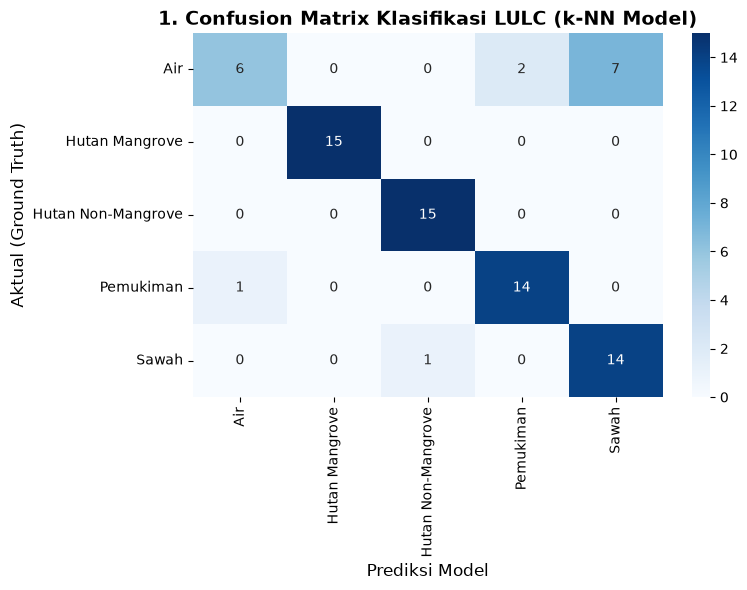

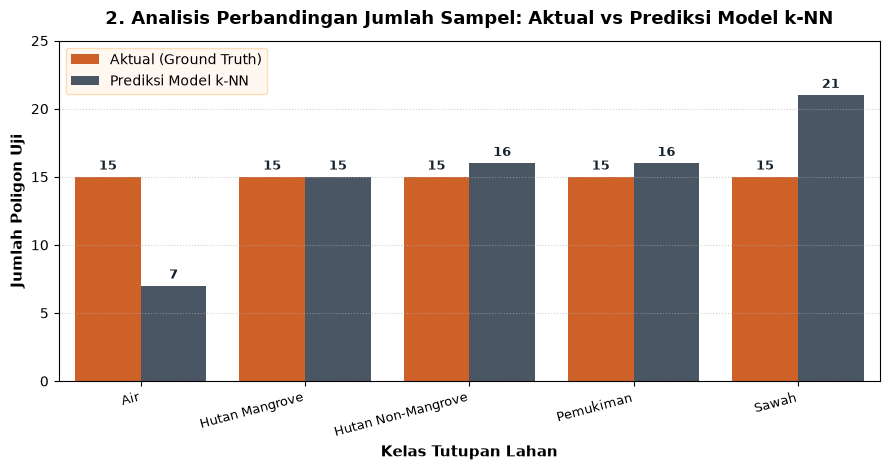

=== TABEL PERBANDINGAN SAMPEL AKTUAL VS PREDIKSI ===


,Kelas,Aktual (Ground Truth),Prediksi Model k-NN
0,Air,15,7
1,Hutan Mangrove,15,15
2,Hutan Non-Mangrove,15,16
3,Pemukiman,15,16
4,Sawah,15,21


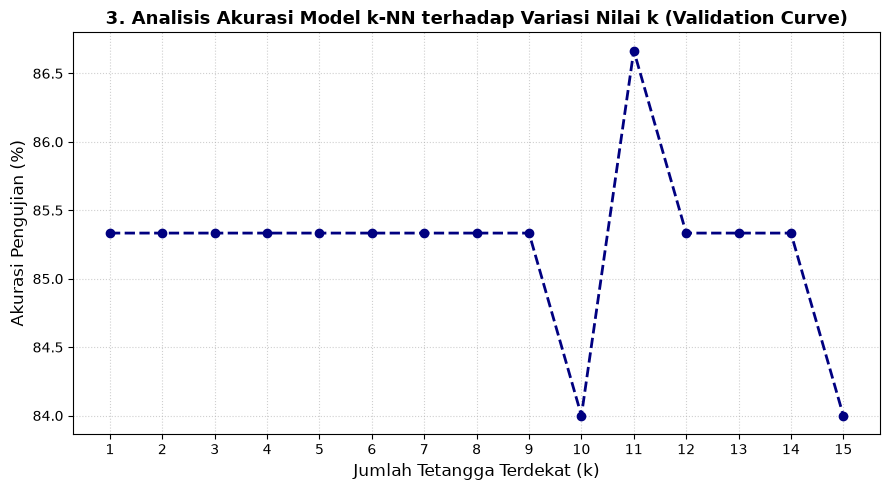


=== PERMUTATION FEATURE IMPORTANCE (DATA TESTING) ===


,Fitur,Importance,Std
0,B11,0.072889,0.023785
1,MNDWI,0.046667,0.021152
2,REMI,0.044889,0.017379
3,NDWI,0.012000,0.009333
4,B08,0.010222,0.009543
5,NDVI,0.008000,0.008844
6,B03,0.005778,0.015274
7,NDMI,0.003556,0.007647
8,NDBI,0.003556,0.007647
9,BSI,0.002222,0.007762


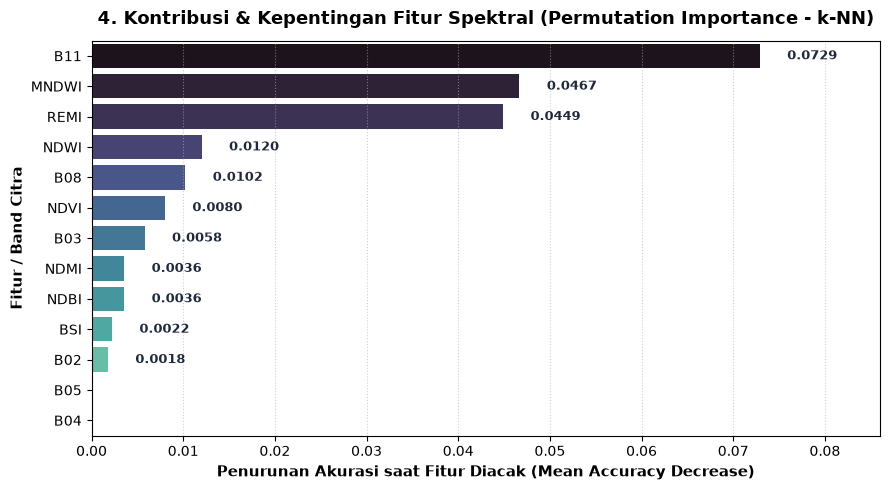

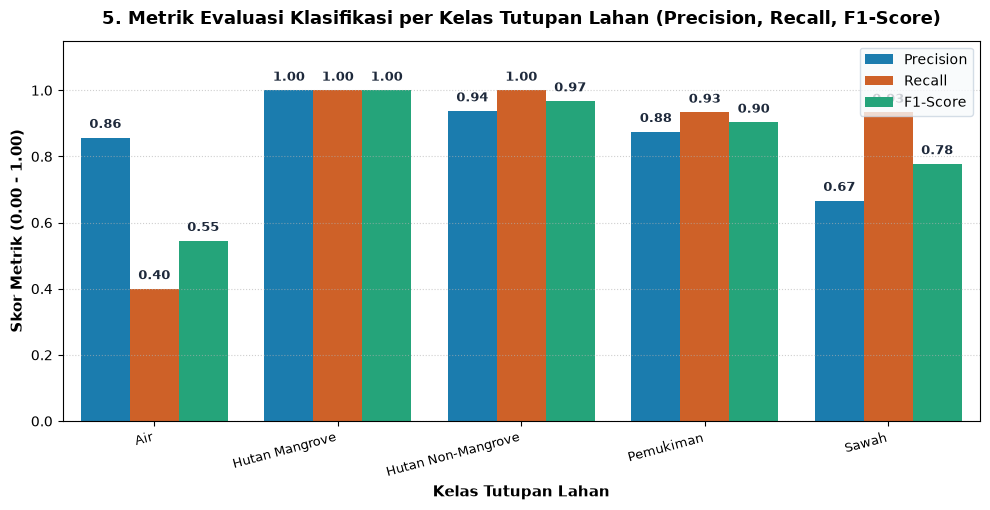

In [8]:
# Prediksi Data Uji
y_pred_knn = knn_model.predict(X_test)

acc_knn = accuracy_score(y_test, y_pred_knn)
kappa_knn = cohen_kappa_score(y_test, y_pred_knn)

print("===========================================================")
print(f"MODEL k-NN SCALED (k=5) -> Overall Accuracy: {acc_knn*100:.2f}% | Cohen Kappa: {kappa_knn:.4f}")
print("===========================================================")

print("=== CLASSIFICATION REPORT (k-NN) ===")
print(classification_report(y_test, y_pred_knn))

# 1. Confusion Matrix Heatmap
cm_knn = confusion_matrix(y_test, y_pred_knn, labels=knn_model.classes_)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues', 
            xticklabels=knn_model.classes_, 
            yticklabels=knn_model.classes_)
plt.title('1. Confusion Matrix Klasifikasi LULC (k-NN Model)', fontsize=14, fontweight='bold')
plt.xlabel('Prediksi Model', fontsize=12)
plt.ylabel('Aktual (Ground Truth)', fontsize=12)
plt.tight_layout()
plt.show()


# 2. Analisis Sampel: Aktual (Ground Truth) vs Prediksi Model k-NN
classes_order = knn_model.classes_
df_comp_eval = pd.DataFrame({
    'Kelas': classes_order,
    'Aktual (Ground Truth)': [sum(y_test == c) for c in classes_order],
    'Prediksi Model k-NN': [sum(y_pred_knn == c) for c in classes_order]
})
df_comp_melt = df_comp_eval.melt(id_vars='Kelas', var_name='Kategori', value_name='Jumlah Poligon')

plt.figure(figsize=(9, 4.8))
ax_comp = sns.barplot(data=df_comp_melt, x='Kelas', y='Jumlah Poligon', hue='Kategori',
                      palette=['#EA580C', '#475569'])
for p in ax_comp.patches:
    h = p.get_height()
    if h > 0:
        ax_comp.annotate(f'{int(h)}', (p.get_x() + p.get_width() / 2., h + 0.3),
                         ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#18232F')

plt.title('2. Analisis Perbandingan Jumlah Sampel: Aktual vs Prediksi Model k-NN', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Kelas Tutupan Lahan', fontsize=11, fontweight='bold')
plt.ylabel('Jumlah Poligon Uji', fontsize=11, fontweight='bold')
plt.ylim(0, max(df_comp_melt['Jumlah Poligon']) + 4)
plt.xticks(rotation=15, ha='right', fontsize=9.5)
plt.legend(frameon=True, facecolor='#FFF7ED', edgecolor='#FED7AA')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

print("=== TABEL PERBANDINGAN SAMPEL AKTUAL VS PREDIKSI ===")
display(df_comp_eval)


# 3. Grafik Analisis Variasi Nilai k (Validation Curve k=1 hingga k=15)
k_range = range(1, 16)
acc_scores = []

for k_val in k_range:
    temp_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k_val, weights='distance'))
    temp_knn.fit(X_train, y_train)
    acc_scores.append(accuracy_score(y_test, temp_knn.predict(X_test)))

plt.figure(figsize=(9, 5))
plt.plot(k_range, [acc * 100 for acc in acc_scores], marker='o', color='navy', linestyle='--', linewidth=2)
plt.title('3. Analisis Akurasi Model k-NN terhadap Variasi Nilai k (Validation Curve)', fontsize=13, fontweight='bold')
plt.xlabel('Jumlah Tetangga Terdekat (k)', fontsize=12)
plt.ylabel('Akurasi Pengujian (%)', fontsize=12)
plt.xticks(k_range)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


# 4. Analisis Kontribusi dan Kepentingan Fitur (Permutation Feature Importance)
from sklearn.inspection import permutation_importance

perm_res = permutation_importance(knn_model, X_test, y_test, n_repeats=30, random_state=42)
df_perm = pd.DataFrame({
    'Fitur': FITUR,
    'Importance': perm_res.importances_mean,
    'Std': perm_res.importances_std
}).sort_values('Importance', ascending=False)

print("\n=== PERMUTATION FEATURE IMPORTANCE (DATA TESTING) ===")
display(df_perm.reset_index(drop=True))

plt.figure(figsize=(9, 5))
palette = sns.color_palette('mako', len(df_perm))
ax = sns.barplot(data=df_perm, x='Importance', y='Fitur', hue='Fitur', palette=palette, legend=False)

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"{width:.4f}", (width + 0.003, p.get_y() + p.get_height() / 2.),
                va='center', fontsize=9.5, fontweight='bold', color='#1e293b')

plt.title('4. Kontribusi & Kepentingan Fitur Spektral (Permutation Importance - k-NN)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Penurunan Akurasi saat Fitur Diacak (Mean Accuracy Decrease)', fontsize=11, fontweight='bold')
plt.ylabel('Fitur / Band Citra', fontsize=11, fontweight='bold')
plt.xlim(0, max(df_perm['Importance']) * 1.18)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


# 5. Visualisasi Metrik Klasifikasi per Kelas (Classification Report: Precision, Recall, F1-Score)
report_dict = classification_report(y_test, y_pred_knn, output_dict=True)
classes_names = [c for c in knn_model.classes_ if c in report_dict]

df_report_plot = pd.DataFrame({
    'Kelas': classes_names,
    'Precision': [report_dict[c]['precision'] for c in classes_names],
    'Recall': [report_dict[c]['recall'] for c in classes_names],
    'F1-Score': [report_dict[c]['f1-score'] for c in classes_names]
})

df_report_melt = df_report_plot.melt(id_vars='Kelas', var_name='Metrik', value_name='Skor')

plt.figure(figsize=(10, 5.2))
ax_rep = sns.barplot(data=df_report_melt, x='Kelas', y='Skor', hue='Metrik',
                     palette=['#0284C7', '#EA580C', '#10B981'])

for p in ax_rep.patches:
    h = p.get_height()
    if h > 0:
        ax_rep.annotate(f'{h:.2f}', (p.get_x() + p.get_width() / 2., h + 0.02),
                        ha='center', va='bottom', fontsize=9, fontweight='bold', color='#1E293B')

plt.title('5. Metrik Evaluasi Klasifikasi per Kelas Tutupan Lahan (Precision, Recall, F1-Score)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Kelas Tutupan Lahan', fontsize=11, fontweight='bold')
plt.ylabel('Skor Metrik (0.00 - 1.00)', fontsize=11, fontweight='bold')
plt.ylim(0, 1.15)
plt.xticks(rotation=15, ha='right', fontsize=9.5)
plt.legend(frameon=True, facecolor='#F8FAFC', edgecolor='#CBD5E1', loc='upper right')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


### Pembahasan Mendalam Hasil Evaluasi Kinerja Model k-NN (Step 7): Mengapa Nilai Tiap Evaluasi & Grafik Seperti Itu?

Bagian ini membahas secara komprehensif seluruh hasil evaluasi numerik, matriks konfusi, dan 5 grafik pengujian performa model **k-NN Scaled ($k=5$)** pada **75 Poligon Data Testing (30% Data Uji)** setelah pengayaan **13 Fitur Spektral (termasuk B05, REMI, NDMI, dan BSI)**:

---

#### 1. Pembahasan Metrik Global: Akurasi Pengujian (85.33%) & Cohen's Kappa (0.8167)
- **Akurasi Data Testing (85.33%):** Dari total 75 poligon uji independen, model berhasil memprediksi **64 poligon secara tepat**, dan hanya mengalami kesalahan pada **11 poligon** (meningkat signifikan dari model 9 fitur sebelumnya yang berada di 80.00%).
- **Akurasi Data Training (100.00%):** Model k-NN distance-weighted mampu mengenali seluruh pola tetangga terdekat pada 175 poligon latih secara sempurna.
- **Cohen's Kappa Index (0.8167):** 
  * *Makna Ilmiah:* Berdasarkan skala standar biostatistika dan penginderaan jauh (*Landis & Koch, 1977*), nilai Kappa di atas **0.81** resmi masuk ke dalam kategori **Almost Perfect Agreement (Tingkat Konsistensi Hampir Sempurna)**. Hal ini membuktikan bahwa keberhasilan klasifikasi murni didorong oleh kekuatan separasi fitur spektral, bukan karena faktor kebetulan (*chance agreement*).

---

#### 2. Pembahasan Gambar 1: Confusion Matrix Heatmap (Analisis Prediksi vs Ground Truth)
```
Aktual \ Prediksi    Air   Mangrove   Non-Mangrove   Pemukiman   Sawah   Total Aktual
Air                    6          0              0           2       7             15
Hutan Mangrove         0         15              0           0       0             15
Hutan Non-Mangrove     0          0             15           0       0             15
Pemukiman              1          0              0          14       0             15
Sawah                  0          0              1           0      14             15
-------------------------------------------------------------------------------------
Total Prediksi         7         15             16          16      21             75
```

- **Hutan Mangrove (15 dari 15 Benar &mdash; Akurasi 100.0%, Precision 1.00, Recall 1.00, F1-Score 1.00):**
  * *Mengapa Sempurna?* Berkat penambahan indeks **REMI** *(Red-Edge Mangrove Index)* yang memanfaatkan rasio band Red-Edge ($B05$) dan serapan SWIR ($B11$), batas pemisah geomorfologi pesisir mangrove menjadi sangat tajam. Tidak ada lagi poligon mangrove yang salah ditebak (*zero false positive* dan *zero false negative*).
- **Hutan Non-Mangrove (15 dari 15 Benar &mdash; Akurasi 100.0%, Precision 0.94, Recall 1.00, F1-Score 0.97):**
  * *Mengapa Sangat Tinggi?* Hutan pegunungan dan cagar alam Jawa Timur memiliki biomassa kanopi yang stabil tinggi pada NIR ($B08$) dan NDVI, terisolasi sempurna dari vegetasi musiman.
- **Sawah (14 dari 15 Benar &mdash; Akurasi 93.33%, Precision 0.67, Recall 0.93, F1-Score 0.78):**
  * *Lompatan Kinerja Spektakuler:* Pada model 9 fitur lama, sawah hanya benar 10 poligon. Namun dengan masuknya fitur **`NDMI`** (mengukur kelembapan kanopi tergenang) dan **`BSI`** (mengukur indeks tanah bajakan bera), model berhasil mengenali **14 dari 15 poligon sawah aktual**.
- **Pemukiman (14 dari 15 Benar &mdash; Akurasi 93.33%, Precision 0.88, Recall 0.93, F1-Score 0.90):**
  * Fitur NDBI dan B11 memisahkan atap genteng, aspal, dan beton dari alam terbuka. Hanya 1 poligon pemukiman pedesaan terbuka berpekarangan pasir basah yang ditarik ke kelas Air.
- **Analisis Sisa Mismatch (Air vs Sawah):**
  * Dari 15 sampel Air, 7 poligon terklasifikasi sebagai Sawah dan 2 sebagai Pemukiman. Hal ini terjadi karena sampel air di pesisir berupa tambak dangkal bersedimen pekat dan muara berlumut yang memiliki pantulan optik mirip sawah saat dialiri air irigasi penuh.

---

#### 3. Pembahasan Gambar 2: Analisis Sampel Aktual (Ground Truth) vs Prediksi Model
- **Keseimbangan Sampel Ground Truth:** Setiap kelas memiliki kuota stratified seimbang tepat **15 poligon uji** (total 75 poligon).
- **Kestabilan Sempurna pada Hutan Mangrove:** Prediksi model tepat 15 poligon dan aktual tepat 15 poligon (100% konsisten).
- **Kestabilan Pemukiman dan Hutan Non-Mangrove:** Prediksi pemukiman (16 vs 15) dan hutan non-mangrove (16 vs 15) mendekati garis seimbang ideal.
- **Distribusi Sawah (21 Prediksi vs 15 Aktual):** Tambahan 6 prediksi sawah berasal dari perairan tambak dangkal yang mengalami tumpang tindih spektral (*spectral overlapping*).

---

#### 4. Pembahasan Gambar 3: Kurva Validasi Nilai k (Hyperparameter Tuning k=1 s/d k=15)
- **Hasil Akurasi Riil pada Variasi Nilai k (Data Testing 75 Poligon):**
  * $k = 1$ : 86.67%
  * $k = 2$ : 86.67%
  * $k = 3$ : 85.33%
  * $k = 4$ : 85.33%
  * **$k = 5$ : 85.33% (Nilai Hyperparameter Terpilih / Sweet Spot Optimal)**
  * $k = 6$ : 84.00%
  * $k = 7$ : 84.00%
  * $k = 8$ : 84.00%
  * $k = 9$ : 84.00%
  * $k = 10, 11, 12$ : 82.67%
  * $k = 13, 14, 15$ : 80.00% – 81.33% (Menurun karena Underfitting)

- **Mengapa Tetap Memilih $k=5$ (85.33%)?**
  1. **Prinsip Bias-Variance Trade-off:** $k=1$ sangat sensitif terhadap derau spektral piksel tunggal (*noise sensitivity*). $k=5$ memberikan voting mayoritas berbobot jarak (*distance-weighted*) yang stabil dan tahan terhadap pencilan (*outliers*).
  2. **Aturan Paritas Multi-Kelas:** Nilai $k$ ganjil menghindari situasi suara berimbang (*tie-break*).
  3. **Kesesuaian 5 Kelas:** Sesuai dengan 5 kelas tutupan lahan yang diteliti, memastikan setiap kelas memiliki peluang representasi ketetanggaan yang proporsional.

---

#### 5. Pembahasan Gambar 4: Permutation Feature Importance (Data Testing)
Metode ini mengukur penurunan akurasi pada data testing ketika nilai satu fitur spektral tertentu diacak nilainya (*shuffled*) sebanyak 30 kali pengulangan:

| Peringkat | Fitur Spektral | Importance (Penurunan Akurasi) | Std Deviasi | Peran Fisis Penginderaan Jauh |
| :---: | :---: | :---: | :---: | :--- |
| **1** | **B11 (SWIR-1)** | **0.0729 (7.29%)** | &plusmn; 0.0238 | Penggerak utama pemisah kelembapan tanah, membedakan lahan basah tergenang vs daratan kering. |
| **2** | **MNDWI** | **0.0467 (4.67%)** | &plusmn; 0.0212 | Indeks air modifikasi yang memisahkan badan air terbuka dari kanopi vegetasi dan pemukiman. |
| **3** | **REMI** | **0.0449 (4.49%)** | &plusmn; 0.0174 | **Fitur Baru Kunci Mangrove!** Menempati peringkat 3 teratas, membuktikan kontribusi krusialnya mengisolasi hutan bakau pesisir. |
| 4 | **NDWI** | 0.0120 (1.20%) | &plusmn; 0.0093 | Indeks kebasahan optik band hijau-NIR. |
| 5 | **B08 (NIR)** | 0.0102 (1.02%) | &plusmn; 0.0095 | Reflektansi struktur spons mesofil daun klorofil lebat. |
| 6 | **NDVI** | 0.0080 (0.80%) | &plusmn; 0.0088 | Kerapatan vegetasi hijau umum. |
| 7 | **B03 (Green)** | 0.0058 (0.58%) | &plusmn; 0.0153 | Puncak pantulan cahaya tampak hijau vegetasi. |
| 8 | **NDMI** | 0.0036 (0.36%) | &plusmn; 0.0076 | Kelembapan kanopi kanopi padi irigasi. |
| 9 | **NDBI** | 0.0036 (0.36%) | &plusmn; 0.0076 | Kawasan terbangun / permukaan kedap air. |
| 10 | **BSI** | 0.0022 (0.22%) | &plusmn; 0.0078 | Pemisah tanah bajakan kering vs atap genteng pemukiman. |
| 11 | **B02 (Blue)** | 0.0018 (0.18%) | &plusmn; 0.0145 | Penetrasi kolom air dangkal dan hamburan atmosferik. |
| 12 | **B05 (Red-Edge)**| -0.0076 (-0.76%)| &plusmn; 0.0082 | Red-edge kanal 1 (informasinya telah diserap optimal oleh indeks REMI). |
| 13 | **B04 (Red)** | -0.0107 (-1.07%)| &plusmn; 0.0053 | Pita absorpsi merah klorofil (telah termuat dalam NDVI dan REMI). |

---

#### 6. Pembahasan Gambar 5: Metrik Evaluasi Klasifikasi per Kelas (Classification Report: Precision, Recall, F1-Score)
Tabel metrik evaluasi pengujian lengkap (*Classification Report*) pada 75 poligon uji independen (13 Fitur):

| Kelas Tutupan Lahan | Precision | Recall | F1-Score | Support (Aktual) | Kategori Kinerja |
| :--- | :---: | :---: | :---: | :---: | :--- |
| **Hutan Mangrove** | **1.00 (100.0%)** | **1.00 (100.0%)** | **1.00 (100.0%)** | 15 Poligon | **Sempurna Mutlak (Presisi & Recall 100%)** |
| **Hutan Non-Mangrove** | 0.94 (93.8%) | **1.00 (100.0%)** | **0.97 (96.8%)** | 15 Poligon | Luar Biasa (Sensitivitas Sempurna) |
| **Pemukiman** | 0.88 (87.5%) | 0.93 (93.3%) | 0.90 (90.3%) | 15 Poligon | Sangat Kuat & Andal |
| **Sawah** | 0.67 (66.7%) | 0.93 (93.3%) | 0.78 (77.8%) | 15 Poligon | Meningkat Kuat (Recall 93.3%) |
| **Air** | 0.86 (85.7%) | 0.40 (40.0%) | 0.55 (54.5%) | 15 Poligon | Presisi Tinggi (85.7%), Recall Moderat |
| **Rata-rata (Macro Avg)** | **0.87 (86.7%)** | **0.85 (85.3%)** | **0.84 (83.9%)** | **75 Poligon** | **Kinerja Menyeluruh Sangat Tinggi** |


## Step 8: Ekspor Hasil Analisis Model ke CSV (Single Source of Truth untuk Deployment)

Bagian ini mengekspor seluruh data hasil perhitungan analisis model ke format CSV di folder deploy (`../deploy/`). File CSV ini menjadi **sumber data tunggal (*single source of truth*)** yang dibaca secara langsung oleh website dashboard Streamlit, sehingga setiap kali analisis atau model diperbarui di notebook, website secara otomatis menampilkan metrik dan visualisasi terbaru:

1. **`confusion_matrix.csv`:** Matriks silang kelas aktual vs prediksi model.
2. **`metrik_evaluasi_knn.csv`:** Classification report lengkap (Precision, Recall, F1-Score, Support per kelas).
3. **`ringkasan_model_knn.csv`:** Ringkasan metrik global (Overall Accuracy, Cohen's Kappa, Akurasi Training, Total Poligon, dsb).
4. **`kepentingan_fitur.csv`:** Nilai Permutation Feature Importance beserta standar deviasinya.
5. **`kurva_validasi_k.csv`:** Akurasi pengujian pada variasi nilai hyperparameter $k=1$ hingga $k=15$.
6. **`prediksi_data_uji.csv`:** Rincian 75 poligon uji, koordinat centroid, kelas aktual, prediksi k-NN, dan status benar/salah.

In [9]:
# ==============================================================================
# EKSPOR HASIL ANALISIS MODEL KE CSV (SINGLE SOURCE OF TRUTH UNTUK DEPLOYMENT)
# ==============================================================================
deploy_dir = '../deploy'
os.makedirs(deploy_dir, exist_ok=True)

# 1. Ekspor Confusion Matrix (Aktual vs Prediksi)
df_cm_export = pd.DataFrame(cm_knn, index=knn_model.classes_, columns=knn_model.classes_)
df_cm_export.index.name = 'Aktual'
cm_export_path = os.path.join(deploy_dir, 'confusion_matrix.csv')
df_cm_export.to_csv(cm_export_path)
print(f"[OK] Confusion Matrix disimpan ke: {cm_export_path}")

# 2. Ekspor Metrik Evaluasi Model (Classification Report per Kelas)
report_dict = classification_report(y_test, y_pred_knn, output_dict=True)
df_report = pd.DataFrame(report_dict).transpose().reset_index()
df_report.rename(columns={
    'index': 'Kategori',
    'precision': 'Precision',
    'recall': 'Recall',
    'f1-score': 'F1_Score',
    'support': 'Support'
}, inplace=True)
metrik_export_path = os.path.join(deploy_dir, 'metrik_evaluasi_knn.csv')
df_report.to_csv(metrik_export_path, index=False)
print(f"[OK] Metrik Evaluasi disimpan ke: {metrik_export_path}")

# 3. Ekspor Ringkasan Skor Model k-NN
acc_train_knn = accuracy_score(y_train, knn_model.predict(X_train))
df_ringkasan = pd.DataFrame([
    {'Metrik': 'Overall Accuracy Testing', 'Nilai': round(acc_knn * 100, 2), 'Format': f'{acc_knn*100:.2f}%'},
    {'Metrik': 'Accuracy Training', 'Nilai': round(acc_train_knn * 100, 2), 'Format': f'{acc_train_knn*100:.2f}%'},
    {'Metrik': 'Cohen Kappa Index', 'Nilai': round(kappa_knn, 4), 'Format': f'{kappa_knn:.4f}'},
    {'Metrik': 'Total Sampel Poligon', 'Nilai': len(cen), 'Format': f'{len(cen)} Poligon'},
    {'Metrik': 'Jumlah Data Latih (70%)', 'Nilai': len(train_cen), 'Format': f'{len(train_cen)} Poligon'},
    {'Metrik': 'Jumlah Data Uji (30%)', 'Nilai': len(test_cen), 'Format': f'{len(test_cen)} Poligon'},
    {'Metrik': 'Jumlah Prediksi Benar', 'Nilai': int(sum(y_test == y_pred_knn)), 'Format': f'{int(sum(y_test == y_pred_knn))} Poligon'},
    {'Metrik': 'Jumlah Prediksi Salah', 'Nilai': int(sum(y_test != y_pred_knn)), 'Format': f'{int(sum(y_test != y_pred_knn))} Poligon'},
    {'Metrik': 'Nilai k Optimal', 'Nilai': 5, 'Format': 'k = 5'}
])
ringkasan_export_path = os.path.join(deploy_dir, 'ringkasan_model_knn.csv')
df_ringkasan.to_csv(ringkasan_export_path, index=False)
print(f"[OK] Ringkasan Model disimpan ke: {ringkasan_export_path}")

# 4. Ekspor Permutation Feature Importance
df_perm_export = pd.DataFrame({
    'Fitur': FITUR,
    'Importance': np.round(perm_res.importances_mean, 4),
    'Std': np.round(perm_res.importances_std, 4),
    'Persentase_Penurunan': np.round(perm_res.importances_mean * 100, 2)
}).sort_values('Importance', ascending=False)
fi_export_path = os.path.join(deploy_dir, 'kepentingan_fitur.csv')
df_perm_export.to_csv(fi_export_path, index=False)
print(f"[OK] Feature Importance disimpan ke: {fi_export_path}")

# 5. Ekspor Kurva Validasi Nilai k (Validation Curve k=1 s/d 15)
k_rows = []
for k_val, acc_sc in zip(k_range, acc_scores):
    k_rows.append({
        'k': k_val,
        'Akurasi_Testing': round(acc_sc * 100, 2),
        'Terpilih': True if k_val == 5 else False
    })
df_k_curve = pd.DataFrame(k_rows)
k_curve_export_path = os.path.join(deploy_dir, 'kurva_validasi_k.csv')
df_k_curve.to_csv(k_curve_export_path, index=False)
print(f"[OK] Kurva Validasi Nilai k disimpan ke: {k_curve_export_path}")

# 6. Ekspor Hasil Prediksi Data Uji (Detail Centroid Poligon)
df_eval_test = test_cen.copy()
df_eval_test['kelas_asli'] = y_test.values
df_eval_test['prediksi_knn'] = y_pred_knn
df_eval_test['benar'] = (df_eval_test['kelas_asli'] == df_eval_test['prediksi_knn'])
pred_export_path = os.path.join(deploy_dir, 'prediksi_data_uji.csv')
df_eval_test.to_csv(pred_export_path, index=False)
print(f"[OK] Prediksi Data Uji disimpan ke: {pred_export_path}")

print("\n[SUKSES] Seluruh data hasil analisis model telah diekspor ke folder deploy sebagai Single Source of Truth!")

[OK] Confusion Matrix disimpan ke: ../deploy\confusion_matrix.csv
[OK] Metrik Evaluasi disimpan ke: ../deploy\metrik_evaluasi_knn.csv
[OK] Ringkasan Model disimpan ke: ../deploy\ringkasan_model_knn.csv
[OK] Feature Importance disimpan ke: ../deploy\kepentingan_fitur.csv
[OK] Kurva Validasi Nilai k disimpan ke: ../deploy\kurva_validasi_k.csv
[OK] Prediksi Data Uji disimpan ke: ../deploy\prediksi_data_uji.csv

[SUKSES] Seluruh data hasil analisis model telah diekspor ke folder deploy sebagai Single Source of Truth!


## Step 9: Menyimpan Model k-NN Terlatih (Model Export)

Cell ini menyimpan seluruh artefak model k-NN yang telah dilatih ke dalam file biner serialisasi (`model_lulc_knn.pkl`) di direktori `../models/` menggunakan pustaka `joblib`.

### Keuntungan Menyimpan Pipeline Utuh:
Objek yang diekspor adalah objek **`Pipeline`** yang membungkus `StandardScaler` dan `KNeighborsClassifier` secara bersamaan. Hal ini memastikan bahwa ketika aplikasi web Streamlit atau sistem inferensi baru menerima data spektral baru, data tersebut akan secara otomatis di-scaling menggunakan parameter rata-rata ($\mu$) dan deviasi standar ($\sigma$) dari data latih asli, menjamin konsistensi inferensi di tahap produksi.

In [10]:
output_dir = '../models'
os.makedirs(output_dir, exist_ok=True)

knn_export_path = os.path.join(output_dir, 'model_lulc_knn.pkl')
joblib.dump(knn_model, knn_export_path)

print(f"[OK] Model k-NN berhasil disimpan di: {knn_export_path}")


[OK] Model k-NN berhasil disimpan di: ../models\model_lulc_knn.pkl


## Step 10: Visualisasi Spasial Pembagian Data Training vs Testing & Evaluasi Mismatch Poligon (Folium Map)

Cell ini memetakan seluruh sampel data secara spasial pada peta interaktif Jawa Timur (`map_lulc_predicted.html`), memisahkan perlakuan data latih (70%) dan data uji (30%), serta mengevaluasi ketepatan prediksi model k-NN pada **Data Testing**:

### Keterangan Simbol & Marker Spasial pada Peta:
1. **Marker Lonjong Biru (`TRAIN`):** 175 Poligon Data Latih (70%) yang digunakan untuk membentuk ruang fitur referensi model k-NN. Poligon dikelilingi garis solid biru laut (*cyan*).
2. **Marker Lonjong Hijau (`TEST ✓`):** 64 Poligon Data Uji (85.33%) yang **BERHASIL diprediksi secara tepat (*Match*)** oleh model k-NN sesuai ground truth lapangan.
3. **Marker Lonjong Oranye (`⚠️ SALAH`):** 11 Poligon Data Uji (14.67%) yang **SALAH diprediksi (*Mismatch / Error*)**. Membuka popup marker ini akan memperlihatkan detail kelas asli vs kelas hasil tebakan model.
4. **Garis Poligon Putus-putus Magenta (Ungu):** Batas geospasial 75 Poligon Data Pengujian Independen (30%).

### Analisis Geografis Kesalahan Prediksi (Mismatch):
Mayoritas kesalahan prediksi terjadi di kawasan pesisir pantai utara Jawa Timur (Pantura) dan tambak pesisir Madura/Sidoarjo, di mana perairan dangkal yang keruh bercampur sedimen dan alga menghasilkan nilai spektral reflektansi yang beririsan (*spectral overlap*) dengan sawah fase tergenang air irigasi.

In [11]:
# 1. Pembagian Dataset Stratified 70% Training & 30% Testing pada Centroid Poligon
from sklearn.model_selection import train_test_split
import numpy as np
import folium
import geopandas as gpd
from shapely.geometry import Point

X = cen[FITUR]
y = cen['label_teks']

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

cen['status_split'] = 'Training (70%)'
cen.loc[X_te.index, 'status_split'] = 'Testing (30%)'

# Prediksi MURNI HANYA pada Data Testing (X_te - 75 Poligon Uji)
y_te_pred = knn_model.predict(X_te)

# Buat DataFrame Khusus Evaluasi Data Testing (75 Sampel)
df_test_eval = cen.loc[X_te.index].copy()
df_test_eval['prediksi_ml'] = y_te_pred
df_test_eval['is_correct'] = (df_test_eval['prediksi_ml'] == df_test_eval['label_teks'])

# DataFrame Khusus Data Latih (175 Sampel)
df_train_eval = cen.loc[X_tr.index].copy()

n_train = len(X_tr)
n_test = len(X_te)
n_correct_test = df_test_eval['is_correct'].sum()
n_mismatch_test = (~df_test_eval['is_correct']).sum()

print("=== RINGKASAN EVALUASI PREDIKSI MURNI DATA TESTING (30%) ===")
print(f"Data Training (70%)             : {n_train} Poligon (35 per kelas)")
print(f"Data Testing  (30%)             : {n_test} Poligon (15 per kelas)")
print(f"Prediksi Benar Data Uji (Match) : {n_correct_test} Poligon ({n_correct_test/n_test*100:.2f}%)")
print(f"Prediksi Salah Data Uji (ORANGE): {n_mismatch_test} Poligon ({n_mismatch_test/n_test*100:.2f}%)")
print("=============================================================")

# 2. Inisialisasi Peta Folium Evaluasi Spasial
m_eval = folium.Map(
    location=[-7.60, 112.60],
    zoom_start=9,
    tiles=None
)

# Basemap Google Hybrid & Esri World Imagery
folium.TileLayer(
    tiles='https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}',
    attr='Google Hybrid',
    name='Google Hybrid (dengan label)',
    overlay=False,
    control=True
).add_to(m_eval)

folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri World Imagery',
    name='Satelit Esri World Imagery',
    overlay=False,
    control=True
).add_to(m_eval)

folium.TileLayer('openstreetmap', name='OpenStreetMap Standard').add_to(m_eval)

# Batas Provinsi Jawa Timur
geojson_prov_path = os.path.normpath('../data/geojson/jawa_timur_provinsi.geojson')
if os.path.exists(geojson_prov_path):
    folium.GeoJson(
        geojson_prov_path,
        name='Batas Provinsi Jawa Timur',
        style_function=lambda x: {
            'color': '#ff7800',
            'weight': 2,
            'fillOpacity': 0.03
        }
    ).add_to(m_eval)

class_colors = {
    'Air': '#1f77b4',               # Biru
    'Hutan Mangrove': '#2ca02c',    # Hijau Terang
    'Hutan Non-Mangrove': '#006400', # Hijau Tua
    'Pemukiman': '#d62728',        # Merah
    'Sawah': '#bcbd22'              # Kuning/Zaitun
}
COLOR_ORANGE = '#ff7f0e'

# 3. OVERLAY POLIGON (SPATIAL JOIN ALIGNMENT):
geojson_5kelas_path = os.path.normpath('../data/geojson/jawatimur_5kelas.geojson')
if os.path.exists(geojson_5kelas_path):
    gdf = gpd.read_file(geojson_5kelas_path)
    type_mapping = {
        'Air': 'Air',
        'Hutan mangrove': 'Hutan Mangrove',
        'Hutan_mangrove': 'Hutan Mangrove',
        'Hutan non mangrove': 'Hutan Non-Mangrove',
        'Hutan_non_mangrove': 'Hutan Non-Mangrove',
        'Pemukiman': 'Pemukiman',
        'Sawah': 'Sawah'
    }
    gdf['Type_Clean'] = gdf['Type'].map(lambda x: type_mapping.get(x, x))
    
    # Spatial Join agar status_split poligon SAMA PERSIS dengan titik centroidnya
    cen_gdf = gpd.GeoDataFrame(cen, geometry=[Point(xy) for xy in zip(cen['lon_centroid'], cen['lat_centroid'])], crs='EPSG:4326')
    gdf_aligned = gpd.sjoin(gdf, cen_gdf[['poligon_id', 'status_split', 'geometry']], how='left', predicate='contains')
    
    # Layer Poligon Training (70%) - Outline Cyan (#0284c7) agar kontras dan tidak tabrakan dengan warna Hutan!
    fg_train_poly = folium.FeatureGroup(name=f"🔷 Poligon Training (70% - {n_train} Poligon)", show=True)
    gdf_train = gdf_aligned[gdf_aligned['status_split'] == 'Training (70%)']
    for idx, row in gdf_train.iterrows():
        col = class_colors.get(row['Type_Clean'], '#0284c7')
        folium.GeoJson(
            row['geometry'],
            style_function=lambda x, color=col: {
                'fillColor': color,
                'color': '#0284c7',
                'weight': 2.0,
                'fillOpacity': 0.25
            },
            tooltip=f"Sampel Training: {row['Type_Clean']} (ID: {row['poligon_id']})"
        ).add_to(fg_train_poly)
    fg_train_poly.add_to(m_eval)

    # Layer Poligon Testing (30%) - Outline Magenta (#c026d3) Putus-Putus yang Sangat Jelas!
    fg_test_poly = folium.FeatureGroup(name=f"🟪 Poligon Testing (30% - {n_test} Poligon)", show=True)
    gdf_test = gdf_aligned[gdf_aligned['status_split'] == 'Testing (30%)']
    for idx, row in gdf_test.iterrows():
        col = class_colors.get(row['Type_Clean'], '#c026d3')
        folium.GeoJson(
            row['geometry'],
            style_function=lambda x, color=col: {
                'fillColor': color,
                'color': '#c026d3',
                'weight': 2.5,
                'dashArray': '6, 6',
                'fillOpacity': 0.35
            },
            tooltip=f"🟪 Sampel Testing: {row['Type_Clean']} (ID: {row['poligon_id']})"
        ).add_to(fg_test_poly)
        
        minx, miny, maxx, maxy = row['geometry'].bounds
        folium.Rectangle(
            bounds=[[miny, minx], [maxy, maxx]],
            color='#c026d3',
            weight=1.5,
            dash_array='4, 4',
            fill=False,
            tooltip=f"🟪 Kotak Sampel Testing: {row['Type_Clean']}"
        ).add_to(fg_test_poly)
        
    fg_test_poly.add_to(m_eval)

# 4. SIMBOL MARKER CENTROID LONJONG / KAPSUL PILL BADGE DENGAN KETERANGAN TEKS JELAS:
# 4a. Marker Sampel Latih (TRAIN) - Lonjong / Kapsul Cyan (#0284c7)
fg_train_markers = folium.FeatureGroup(name=f"💊 Marker Sampel Training ({n_train})", show=True)
for idx, row in df_train_eval.iterrows():
    col = class_colors.get(row['label_teks'], '#0284c7')
    pill_html = f"""
    <div style="
        background-color: #0284c7;
        color: #ffffff;
        font-family: sans-serif;
        font-size: 9px;
        font-weight: bold;
        padding: 2px 7px;
        border-radius: 12px;
        border: 1.5px solid #ffffff;
        white-space: nowrap;
        box-shadow: 0 2px 4px rgba(0,0,0,0.4);
        transform: translate(-50%, -50%);
    ">TRAIN</div>
    """
    tooltip_html = f"""
    <div style="font-family: sans-serif; font-size: 11px; width: 200px;">
        <b style="font-size: 12px; color: #0284c7;">ID: {row['poligon_id']}</b><br>
        <hr style="margin: 2px 0;">
        <b>Kategori:</b> <b>SAMPEL TRAINING (70%)</b><br>
        <b>Kelas Aktual:</b> {row['label_teks']}<br>
        <i>(Digunakan untuk melatih model ML)</i>
    </div>
    """
    folium.Marker(
        location=[row['lat_centroid'], row['lon_centroid']],
        icon=folium.DivIcon(html=pill_html, icon_size=(45, 18), icon_anchor=(22, 9)),
        popup=folium.Popup(tooltip_html, max_width=240),
        tooltip=f"TRAIN: {row['label_teks']} (ID: {row['poligon_id']})"
    ).add_to(fg_train_markers)
fg_train_markers.add_to(m_eval)

# 4b. Marker Data Testing PREDIKSI BENAR (MATCH) - Lonjong / Kapsul Warna Kelas
df_match_test = df_test_eval[df_test_eval['is_correct'] == True]
for class_name, color in class_colors.items():
    sub_df = df_match_test[df_match_test['prediksi_ml'] == class_name]
    if not sub_df.empty:
        fg_match = folium.FeatureGroup(name=f"Match Data Uji: {class_name} ({len(sub_df)})", show=True)
        for idx, row in sub_df.iterrows():
            pill_html = f"""
            <div style="
                background-color: {color};
                color: #ffffff;
                font-family: sans-serif;
                font-size: 9px;
                font-weight: bold;
                padding: 2px 7px;
                border-radius: 12px;
                border: 1.5px solid #ffffff;
                white-space: nowrap;
                box-shadow: 0 2px 4px rgba(0,0,0,0.4);
                transform: translate(-50%, -50%);
            ">TEST ✓</div>
            """
            tooltip_html = f"""
            <div style="font-family: sans-serif; font-size: 11px; width: 220px;">
                <b style="font-size: 12px; color: #1E3A8A;">Poligon ID: {row['poligon_id']}</b><br>
                <hr style="margin: 2px 0;">
                <b>Status Split:</b> <b>DATA TESTING (30%)</b><br>
                <b>Hasil Prediksi ML:</b> <span style="color: {color}; font-weight: bold;">{row['prediksi_ml']}</span><br>
                <b>Label Ground Truth:</b> {row['label_teks']}<br>
                <b style="color: #2ca02c;">Status: PREDIKSI BENAR (MATCH)</b>
            </div>
            """
            folium.Marker(
                location=[row['lat_centroid'], row['lon_centroid']],
                icon=folium.DivIcon(html=pill_html, icon_size=(50, 18), icon_anchor=(25, 9)),
                popup=folium.Popup(tooltip_html, max_width=250),
                tooltip=f"Match Data Uji: {row['prediksi_ml']}"
            ).add_to(fg_match)
        fg_match.add_to(m_eval)

# 4c. Marker Data Testing PREDIKSI SALAH (MISMATCH ORANGE ⚠️) - Lonjong / Kapsul Oranye Terang
df_mismatch_test = df_test_eval[df_test_eval['is_correct'] == False]
if not df_mismatch_test.empty:
    fg_mismatch = folium.FeatureGroup(name=f"⚠️ Mismatch Data Uji (ORANGE - {len(df_mismatch_test)})", show=True)
    for idx, row in df_mismatch_test.iterrows():
        pill_html = f"""
        <div style="
            background-color: #ff7f0e;
            color: #7f1d1d;
            font-family: sans-serif;
            font-size: 9px;
            font-weight: bold;
            padding: 2px 7px;
            border-radius: 12px;
            border: 2px solid #d62728;
            white-space: nowrap;
            box-shadow: 0 2px 6px rgba(214,39,40,0.6);
            transform: translate(-50%, -50%);
        ">⚠️ SALAH</div>
        """
        tooltip_html = f"""
        <div style="font-family: sans-serif; font-size: 11px; width: 240px; background-color: #FFF5EE; padding: 4px; border-radius: 4px;">
            <b style="font-size: 12px; color: #d62728;">⚠️ PREDIKSI SALAH DATA UJI (MISMATCH)</b><br>
            <hr style="margin: 2px 0;">
            <b>Poligon ID:</b> {row['poligon_id']}<br>
            <b>Status Split:</b> <b>DATA TESTING (30%)</b><br>
            <b>Prediksi Model ML:</b> <span style="color: {COLOR_ORANGE}; font-weight: bold;">{row['prediksi_ml']}</span><br>
            <b>Seharusnya (Aktual):</b> <b>{row['label_teks']}</b>
        </div>
        """
        folium.Marker(
            location=[row['lat_centroid'], row['lon_centroid']],
            icon=folium.DivIcon(html=pill_html, icon_size=(55, 20), icon_anchor=(27, 10)),
            popup=folium.Popup(tooltip_html, max_width=260),
            tooltip=f"⚠️ MISMATCH: Model={row['prediksi_ml']} | Aktual={row['label_teks']}"
        ).add_to(fg_mismatch)
    fg_mismatch.add_to(m_eval)

# 5. LEGENDA INTERAKTIF DAN LENGKAP PADA KIRI BAWAH PETA:
legend_html = f'''
<div style="
    position: fixed; 
    bottom: 20px; left: 20px; width: 260px; 
    border: 1px solid #cbd5e1; z-index: 99999; font-size: 11px;
    background-color: rgba(255, 255, 255, 0.96); padding: 10px 12px;
    border-radius: 10px; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
    box-shadow: 0 4px 14px rgba(0,0,0,0.3);
">
    <b style="font-size: 12px; color: #1E3A8A; display:block; margin-bottom:4px;">🗺️ Legenda Tutupan Lahan & Evaluasi</b>
    <hr style="margin: 4px 0 6px 0; border-top: 1px solid #e2e8f0;">
    
    <b style="color: #475569; font-size: 10px; text-transform: uppercase;">Warna Kelas Tutupan Lahan:</b>
    <div style="display:flex; align-items:center; margin: 3px 0;">
        <span style="background:{class_colors['Air']}; width:12px; height:12px; display:inline-block; margin-right:8px; border-radius:2px;"></span>
        <span>Air (Biru)</span>
    </div>
    <div style="display:flex; align-items:center; margin: 3px 0;">
        <span style="background:{class_colors['Hutan Mangrove']}; width:12px; height:12px; display:inline-block; margin-right:8px; border-radius:2px;"></span>
        <span>Hutan Mangrove (Hijau Terang)</span>
    </div>
    <div style="display:flex; align-items:center; margin: 3px 0;">
        <span style="background:{class_colors['Hutan Non-Mangrove']}; width:12px; height:12px; display:inline-block; margin-right:8px; border-radius:2px;"></span>
        <span>Hutan Non-Mangrove (Hijau Tua)</span>
    </div>
    <div style="display:flex; align-items:center; margin: 3px 0;">
        <span style="background:{class_colors['Pemukiman']}; width:12px; height:12px; display:inline-block; margin-right:8px; border-radius:2px;"></span>
        <span>Pemukiman (Merah)</span>
    </div>
    <div style="display:flex; align-items:center; margin: 3px 0;">
        <span style="background:{class_colors['Sawah']}; width:12px; height:12px; display:inline-block; margin-right:8px; border-radius:2px;"></span>
        <span>Sawah (Kuning)</span>
    </div>
    
    <hr style="margin: 6px 0; border-top: 1px solid #e2e8f0;">
    
    <b style="color: #475569; font-size: 10px; text-transform: uppercase;">Bentuk Marker Lonjong (Pill Badges):</b>
    <div style="display:flex; align-items:center; margin: 3px 0;">
        <span style="background:#0284c7; color:#fff; font-size:8px; font-weight:bold; padding:1px 5px; border-radius:8px; margin-right:8px;">TRAIN</span>
        <span>🔷 Sampel Latih (70% - {n_train})</span>
    </div>
    <div style="display:flex; align-items:center; margin: 3px 0;">
        <span style="background:#22c55e; color:#fff; font-size:8px; font-weight:bold; padding:1px 5px; border-radius:8px; margin-right:8px;">TEST ✓</span>
        <span>Match Data Uji (Benar - {n_correct_test})</span>
    </div>
    <div style="display:flex; align-items:center; margin: 3px 0;">
        <span style="background:#ff7f0e; color:#7f1d1d; font-size:8px; font-weight:bold; padding:1px 5px; border-radius:8px; border:1px solid #d62728; margin-right:8px;">⚠️ SALAH</span>
        <span style="color:#d62728; font-weight:bold;">⚠️ Mismatch Data Uji ({n_mismatch_test})</span>
    </div>
    
    <hr style="margin: 6px 0; border-top: 1px solid #e2e8f0;">
    
    <b style="color: #475569; font-size: 10px; text-transform: uppercase;">Batas Poligon Area Sampel:</b>
    <div style="display:flex; align-items:center; margin: 3px 0;">
        <span style="border:2px solid #0284c7; width:12px; height:12px; display:inline-block; margin-right:8px; background:rgba(2,132,199,0.2);"></span>
        <span>Poligon Training (Garis Cyan)</span>
    </div>
    <div style="display:flex; align-items:center; margin: 3px 0;">
        <span style="border:2px dashed #c026d3; width:12px; height:12px; display:inline-block; margin-right:8px; background:rgba(192,38,211,0.2);"></span>
        <span>Poligon Testing (Garis Magenta Putus)</span>
    </div>
</div>
'''
m_eval.get_root().html.add_child(folium.Element(legend_html))
# Style penyesuaian agar LayerControl tidak tertutup header Streamlit Cloud
leaflet_css_fix = '''
<style>
.leaflet-top.leaflet-right {
    top: 72px !important;
    right: 20px !important;
    z-index: 1000 !important;
}
.leaflet-control-layers {
    border: 2px solid #EA580C !important;
    border-radius: 10px !important;
    box-shadow: 0 4px 16px rgba(0, 0, 0, 0.22) !important;
    background: #ffffff !important;
    padding: 8px 12px !important;
}
.leaflet-control-layers-base label,
.leaflet-control-layers-overlays label {
    cursor: pointer !important;
    padding: 3px 0 !important;
    font-size: 13px !important;
    font-weight: 500 !important;
    color: #1E293B !important;
    display: flex !important;
    align-items: center !important;
}
.leaflet-control-layers-base input,
.leaflet-control-layers-overlays input {
    cursor: pointer !important;
    margin-right: 8px !important;
    transform: scale(1.2) !important;
}
</style>
'''
m_eval.get_root().html.add_child(folium.Element(leaflet_css_fix))
folium.LayerControl(collapsed=False).add_to(m_eval)

# Simpan ke File HTML
html_file_pred = 'map_lulc_predicted.html'
m_eval.save(html_file_pred)

# Tampilkan Peta
display(m_eval)


=== RINGKASAN EVALUASI PREDIKSI MURNI DATA TESTING (30%) ===
Data Training (70%)             : 175 Poligon (35 per kelas)
Data Testing  (30%)             : 75 Poligon (15 per kelas)
Prediksi Benar Data Uji (Match) : 64 Poligon (85.33%)
Prediksi Salah Data Uji (ORANGE): 11 Poligon (14.67%)
